# Federated learning for abnormal motion detection from skeletons

Code for the paper *Federated Learning for Abnormal Motion Detection in Healthcare Using Autoencoders: A Study of Performance, Heterogeneity and Privacy* (Oluwapelumi Alagbe, University of Lincoln).

The notebook runs all 315 experiments of the paper (centralised, local-only, FedAvg, FedProx and DP-SGD training of the LSTM, 1D-CNN and Transformer autoencoders) and then builds the tables and figures.

**Before running**
* The keypoint data should be at `My Drive/Fed-Pro/Data4.zip`.
* Use a CPU runtime (Runtime > Change runtime type > CPU). The models are small, so a GPU does not help.
* Run everything with Runtime > Run all. On a free Colab runtime it takes about 1.5 to 2.5 hours.

Results are saved to `My Drive/Fed-Pro/fedskel_results` after every run. If Colab disconnects, reconnect and use Run all again: finished runs are skipped.

## Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

DATA_ZIP = '/content/drive/MyDrive/Fed-Pro/Data4.zip'
SAVE_DIR = '/content/drive/MyDrive/Fed-Pro/fedskel_results'  # results, tables and figures go here
CODE_DIR = '/content/fedskel_v1'
DATA_DIR = '/content/Data'
RUN_PILOT = False  # set to True to also redo the learning-rate pilot (Table A1, about 20 extra minutes)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
%pip install -q opacus==1.6.0

In [3]:
import os

!unzip -q -o "{DATA_ZIP}" -d /content/
print(len(os.listdir(DATA_DIR + '/train')), 'training videos and', len(os.listdir(DATA_DIR + '/test')), 'test videos')

# keep results/ and outputs/ in Google Drive so they survive a disconnect
os.makedirs(CODE_DIR, exist_ok=True)
for name in ['results', 'outputs']:
    os.makedirs(f'{SAVE_DIR}/{name}', exist_ok=True)
    if not os.path.islink(f'{CODE_DIR}/{name}'):
        os.symlink(f'{SAVE_DIR}/{name}', f'{CODE_DIR}/{name}')
os.environ['FEDSKEL_DATA'] = DATA_DIR

9 training videos and 20 test videos


## Code

Each cell below saves one file of the code to `/content/fedskel_v1`.

| File | Contents |
|:--|:--|
| `data.py` | Loading and cleaning the keypoints, 30-frame windows and features |
| `models.py` | The three autoencoders |
| `fl.py` | Client partitions, training (centralised, local, FedAvg, FedProx, DP-SGD) and evaluation |
| `prepare_data.py` | Builds `dataset.pkl` |
| `run_grid.py` | The 315 experiments |
| `shortcut_analysis.py` | Keypoint handling and choice of test videos (Table 2) |
| `dp_sanity.py` | Extra DP checks (Section 4.5) |
| `pilot.py`, `pilot_table.py` | Learning-rate pilot (Table A1) |
| `analysis.py`, `tables_ms.py` | Statistics, tables and Figures 2 to 6 |
| `fig1_overview.py` | Figure 1 |

In [4]:
%%writefile /content/fedskel_v1/data.py
"""Load the OpenPose keypoints, clean them and cut them into 30-frame windows.

Undetected keypoints (written by OpenPose as 0, 0, 0) are interpolated over time, the five face
keypoints are dropped, and each frame is centred on MidHip and scaled by the torso length.
The confidence values are not used as features.
"""
import glob
import os

import numpy as np

BODY25 = ["Nose", "Neck", "RShoulder", "RElbow", "RWrist", "LShoulder", "LElbow", "LWrist", "MidHip",
          "RHip", "RKnee", "RAnkle", "LHip", "LKnee", "LAnkle", "REye", "LEye", "REar", "LEar",
          "LBigToe", "LSmallToe", "LHeel", "RBigToe", "RSmallToe", "RHeel"]
FACE = [0, 15, 16, 17, 18]
KEEP = [j for j in range(25) if j not in FACE]  # 20 body joints
ROOT, NECK = 8, 1
SEQ_LEN, STRIDE = 30, 15

# Reduced test set for the sensitivity analysis: the five recordings that were flagged as
# low quality during exploratory analysis are left out (15 of the 20 test videos remain).
REDUCED_EXCLUDE_NORMAL = ["Curtain", "Walk_Into_Room_and_Sit"]
REDUCED_EXCLUDE_ABNORMAL = ["Curtain", "Fall", "Quick_Standing_Sitting"]


def list_videos(base_dir):
    out = []
    for split in ["train", "test"]:
        root = os.path.join(base_dir, split)
        for d in sorted(os.listdir(root)):
            sk = os.path.join(root, d, "skeletons")
            if not os.path.isdir(sk):
                continue
            label = 1 if d.startswith("ABN_") else 0
            activity = d.replace("ABN_", "").replace("N_Train_", "").replace("N_Test_", "")
            out.append(dict(split=split, folder=sk, name=d, label=label, activity=activity))
    return out


def load_video(folder):
    files = sorted(glob.glob(os.path.join(folder, "*.npy")))
    return np.stack([np.load(f) for f in files]).astype(np.float64)  # (T, 25, 3)


# kinematic parent used when a joint is never detected in a whole video
PARENT = {1: 8, 2: 1, 3: 2, 4: 3, 5: 1, 6: 5, 7: 6, 9: 8, 10: 9, 11: 10, 12: 8, 13: 12, 14: 13,
          19: 14, 20: 14, 21: 14, 22: 11, 23: 11, 24: 11}


def clean_video(arr):
    """Mark undetected keypoints as missing and interpolate them linearly over time.
    A joint that is never detected in the video inherits its kinematic parent's trajectory."""
    xy = arr[..., :2].copy()
    miss = arr[..., 2] <= 0
    xy[miss] = np.nan
    T = xy.shape[0]
    t = np.arange(T)
    for j in range(xy.shape[1]):
        for c in range(2):
            col = xy[:, j, c]
            m = np.isnan(col)
            if m.all():
                continue
            if m.any():
                col[m] = np.interp(t[m], t[~m], col[~m])
    for _ in range(3):
        for j, p in PARENT.items():
            if np.isnan(xy[:, j, 0]).all():
                xy[:, j, :] = xy[:, p, :]
    return xy, miss


def window_starts(T, L=SEQ_LEN, stride=STRIDE):
    return list(range(0, T - L + 1, stride)) if T >= L else []


def window_features(xyw):
    """xyw: (L, 25, 2) cleaned pixel coordinates -> (L, 82) features."""
    L = xyw.shape[0]
    root = xyw[:, ROOT:ROOT + 1, :]
    torso = np.linalg.norm(xyw[:, NECK, :] - xyw[:, ROOT, :], axis=-1)
    s = float(np.median(torso)) + 1e-6
    pos = (xyw[:, KEEP, :] - root) / s                     # (L, 20, 2) body-centred, torso units
    vel = np.gradient(pos, axis=0)                         # (L, 20, 2)
    root_vel = np.gradient(xyw[:, ROOT, :], axis=0) / s    # (L, 2)   global displacement
    return np.concatenate([pos.reshape(L, -1), vel.reshape(L, -1), root_vel], axis=1).astype(np.float32)


def build_dataset(base_dir, val_frac=0.2, val_stride=5):
    """Return a dict of window arrays and metadata.

    Training videos (all normal) are split temporally: the first (1-val_frac) of the frames produce
    training windows (stride 15) and the last val_frac produce validation windows (stride 5, so that
    the 95th-percentile threshold is estimated from more than a handful of windows). No frame is
    shared between a training and a validation window.
    """
    vids = list_videos(base_dir)
    rows = []
    for v in vids:
        arr = load_video(v["folder"])
        xy, miss = clean_video(arr)
        T = xy.shape[0]
        b = int(round((1 - val_frac) * T))
        if v["split"] == "train":
            plan = [(s, "train") for s in range(0, b - SEQ_LEN + 1, STRIDE)] + \
                   [(s, "val") for s in range(b, T - SEQ_LEN + 1, val_stride)]
        else:
            plan = [(s, "test") for s in window_starts(T)]
        for s, part in plan:
            feat = window_features(xy[s:s + SEQ_LEN])
            # artefact descriptors kept only for the shortcut analysis (never used as model input)
            conf = arr[s:s + SEQ_LEN, :, 2]
            rows.append(dict(part=part, video=v["name"], activity=v["activity"], label=v["label"],
                             start=s, feat=feat,
                             frac_missing_all=float((conf <= 0).mean()),
                             mean_conf=float(conf.mean())))
    X = {p: np.stack([r["feat"] for r in rows if r["part"] == p]) for p in ["train", "val", "test"]}
    meta = {p: [{k: r[k] for k in r if k != "feat"} for r in rows if r["part"] == p] for p in ["train", "val", "test"]}
    # standardisation on training windows only (equivalently: securely aggregated client sums)
    mu = X["train"].reshape(-1, X["train"].shape[-1]).mean(0)
    sd = X["train"].reshape(-1, X["train"].shape[-1]).std(0) + 1e-6
    for p in X:
        X[p] = np.clip((X[p] - mu) / sd, -10, 10).astype(np.float32)
    return X, meta, (mu, sd)


def reduced_subset_mask(meta_test):
    """Boolean mask selecting the test windows of the reduced test set (15 of 20 videos)."""
    keep = []
    for r in meta_test:
        excl = REDUCED_EXCLUDE_ABNORMAL if r["label"] == 1 else REDUCED_EXCLUDE_NORMAL
        keep.append(not any(e in r["video"] for e in excl))
    return np.array(keep)

Overwriting /content/fedskel_v1/data.py


In [5]:
%%writefile /content/fedskel_v1/models.py
"""LSTM, 1D-CNN and Transformer autoencoders. Input and output shape: (batch, 30, features)."""
import math
import torch
import torch.nn as nn


class LSTMAE(nn.Module):
    def __init__(self, n_feat, hidden=128, latent=64):
        super().__init__()
        self.enc = nn.LSTM(n_feat, hidden, batch_first=True)
        self.to_z = nn.Linear(hidden, latent)
        self.from_z = nn.Linear(latent, hidden)
        self.dec = nn.LSTM(hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, n_feat)

    def forward(self, x):
        h, _ = self.enc(x)
        z = self.to_z(h[:, -1, :])
        rep = self.from_z(z).unsqueeze(1).repeat(1, x.shape[1], 1)
        d, _ = self.dec(rep)
        return self.out(d)


class CNN1DAE(nn.Module):
    def __init__(self, n_feat, latent=64, seq_len=30):
        super().__init__()
        assert seq_len == 30, "decoder output_padding is tuned for L=30"
        self.encoder = nn.Sequential(
            nn.Conv1d(n_feat, 64, 5, stride=2, padding=2), nn.ReLU(),
            nn.Conv1d(64, 128, 5, stride=2, padding=2), nn.ReLU(),
            nn.Conv1d(128, latent, 3, stride=2, padding=1), nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose1d(latent, 128, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            nn.ConvTranspose1d(128, 64, 5, stride=2, padding=2, output_padding=0), nn.ReLU(),
            nn.ConvTranspose1d(64, n_feat, 5, stride=2, padding=2, output_padding=1),
        )

    def forward(self, x):
        z = self.encoder(x.transpose(1, 2))
        return self.decoder(z).transpose(1, 2)


class TransformerAE(nn.Module):
    def __init__(self, n_feat, seq_len=30, d_model=64, nhead=4, num_layers=2, latent=64):
        super().__init__()
        self.inp = nn.Linear(n_feat, d_model)
        self.pos_enc = nn.Embedding(seq_len, d_model)
        self.enc = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=2 * d_model, dropout=0.0, batch_first=True),
            num_layers, enable_nested_tensor=False)
        self.to_z = nn.Linear(d_model, latent)
        self.from_z = nn.Linear(latent, d_model)
        self.pos_dec = nn.Embedding(seq_len, d_model)
        self.dec = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=2 * d_model, dropout=0.0, batch_first=True),
            num_layers, enable_nested_tensor=False)
        self.out = nn.Linear(d_model, n_feat)
        self.register_buffer("pos_idx", torch.arange(seq_len), persistent=False)

    def forward(self, x):
        B, L, _ = x.shape
        pos = self.pos_idx[:L].unsqueeze(0).expand(B, L)
        h = self.enc(self.inp(x) + self.pos_enc(pos))
        z = self.to_z(h.mean(dim=1))
        hd = self.from_z(z).unsqueeze(1) + self.pos_dec(pos)
        return self.out(self.dec(hd))


BUILDERS = {
    "LSTM-AE": lambda F: LSTMAE(F),
    "1D-CNN-AE": lambda F: CNN1DAE(F),
    "Transformer-AE": lambda F: TransformerAE(F),
}


def n_params(model):
    return sum(p.numel() for p in model.parameters())

Overwriting /content/fedskel_v1/models.py


In [6]:
%%writefile /content/fedskel_v1/fl.py
"""Client partitions, training (centralised, local, FedAvg, FedProx, DP-SGD) and evaluation.

The learning rate, epoch and round are chosen on the validation loss only. The privacy budget
of each client is added up over all rounds.
"""
import copy
import math
import time
import warnings

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")

try:
    from opacus import PrivacyEngine
    from opacus.accountants import PRVAccountant, RDPAccountant
    from opacus.validators import ModuleValidator
    from torch.utils.data import DataLoader, TensorDataset
except Exception:  # pragma: no cover
    PrivacyEngine = None

from models import BUILDERS

N_CLIENTS = 5


# ----------------------------------------------------------------------------- partitions
def make_partition(kind, train_acts, val_acts, seed, n_clients=N_CLIENTS, alpha=0.5, min_size=5):
    """Return (list of train index arrays, list of val index arrays, activity-weight dicts)."""
    rng = np.random.default_rng(1000 + seed)
    train_acts = np.asarray(train_acts)
    val_acts = np.asarray(val_acts)
    acts = sorted(set(train_acts))
    n = len(train_acts)

    def split_iid(idx_all, props):
        idx_all = rng.permutation(idx_all)
        cuts = (np.cumsum(props)[:-1] * len(idx_all)).round().astype(int)
        return np.split(idx_all, cuts)

    if kind == "iid":
        tr = split_iid(np.arange(n), np.ones(n_clients) / n_clients)
        va = split_iid(np.arange(len(val_acts)), np.ones(n_clients) / n_clients)
    elif kind == "quantity":
        for _ in range(1000):
            p = rng.dirichlet(alpha * np.ones(n_clients))
            if (p * n).min() >= min_size:
                break
        tr = split_iid(np.arange(n), p)
        va = split_iid(np.arange(len(val_acts)), p)
    elif kind == "act_dirichlet":
        for _ in range(1000):
            tr = [[] for _ in range(n_clients)]
            va = [[] for _ in range(n_clients)]
            for a in acts:
                p = rng.dirichlet(alpha * np.ones(n_clients))
                for store, pool in ((tr, np.where(train_acts == a)[0]), (va, np.where(val_acts == a)[0])):
                    pool = rng.permutation(pool)
                    cuts = (np.cumsum(p)[:-1] * len(pool)).round().astype(int)
                    for k, part in enumerate(np.split(pool, cuts)):
                        store[k].extend(part.tolist())
            if min(len(t) for t in tr) >= min_size and min(len(v) for v in va) >= 1:
                break
        tr = [np.array(sorted(t), dtype=int) for t in tr]
        va = [np.array(sorted(v), dtype=int) for v in va]
    elif kind == "act_disjoint":
        order = rng.permutation(acts)
        groups = [order[k::n_clients] for k in range(n_clients)]  # 9 activities -> sizes 2,2,2,2,1
        tr = [np.where(np.isin(train_acts, g))[0] for g in groups]
        va = [np.where(np.isin(val_acts, g))[0] for g in groups]
    else:
        raise ValueError(kind)
    weights = []
    for t in tr:
        a, c = np.unique(train_acts[t], return_counts=True)
        weights.append({aa: cc / c.sum() for aa, cc in zip(a, c)})
    return [np.asarray(t, dtype=int) for t in tr], [np.asarray(v, dtype=int) for v in va], weights


# ----------------------------------------------------------------------------- training
def build_model(name, n_feat, seed, dp=False):
    torch.manual_seed(seed)
    m = BUILDERS[name](n_feat)
    if dp:
        m = ModuleValidator.fix(m)
    return m


@torch.no_grad()
def recon_errors(model, X, bs=256):
    model.eval()
    out = []
    Xt = torch.from_numpy(X)
    for i in range(0, len(Xt), bs):
        x = Xt[i:i + bs]
        out.append(((model(x) - x) ** 2).mean(dim=(1, 2)).numpy())
    model.train()
    return np.concatenate(out) if out else np.zeros(0)


def local_train(model, X, epochs, lr, bs, seed, mu=0.0, global_params=None, dp=None, opt_name="adam"):
    """Train a copy of the model on X and return its weights (and the DP history if dp is set).
    For FedProx, mu * (w - w_global) is added to the gradient before the optimiser step."""
    m = copy.deepcopy(model)
    m.train()
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(m.parameters(), lr=lr) if opt_name == "adam" else torch.optim.SGD(m.parameters(), lr=lr, momentum=0.0)
    Xt = torch.from_numpy(X)
    hist = None
    if dp is None:
        params = list(m.parameters())
        for _ in range(epochs):
            perm = torch.randperm(len(Xt), generator=g)
            for i in range(0, len(Xt), bs):
                x = Xt[perm[i:i + bs]]
                opt.zero_grad()
                loss = nn.functional.mse_loss(m(x), x)
                loss.backward()
                if mu > 0 and global_params is not None:
                    for p, p0 in zip(params, global_params):
                        p.grad.add_(mu * (p.data - p0))
                opt.step()
        return {k: v.detach().clone() for k, v in m.state_dict().items()}, None

    dl = DataLoader(TensorDataset(Xt), batch_size=bs, shuffle=True, generator=g)
    pe = PrivacyEngine(accountant="prv")
    m, opt, dl = pe.make_private(module=m, optimizer=opt, data_loader=dl,
                                 noise_multiplier=dp["noise"], max_grad_norm=dp["clip"])
    params = list(m._module.parameters())
    for _ in range(epochs):
        for (x,) in dl:
            if len(x) == 0:  # probability ~ (1-q)^n, negligible here
                continue
            opt.zero_grad()
            loss = nn.functional.mse_loss(m(x), x)
            loss.backward()
            if opt.pre_step():  # clip per-sample grads, add noise, record accountant step
                if mu > 0 and global_params is not None:
                    for p, p0 in zip(params, global_params):
                        p.grad.add_(mu * (p.data - p0))  # data-independent: no privacy cost
                opt.original_optimizer.step()
    hist = list(pe.accountant.history)
    sd = {k: v.detach().clone() for k, v in m._module.state_dict().items()}
    return sd, hist


def epsilon_from_history(hist, delta=1e-5, accountant="prv"):
    if not hist:
        return None
    # merge entries with identical (sigma, q)
    merged = {}
    for s, q, n in hist:
        merged[(s, q)] = merged.get((s, q), 0) + n
    A = PRVAccountant() if accountant == "prv" else RDPAccountant()
    A.history = [(s, q, n) for (s, q), n in merged.items()]
    return float(A.get_epsilon(delta=delta))


def fit_centralised(name, Xtr, Xva, seed, lr, epochs=100, bs=16, dp=None, patience=None):
    m = build_model(name, Xtr.shape[-1], seed, dp=dp is not None)
    best = (np.inf, None, -1)
    hist_all = []
    for ep in range(epochs):
        sd, hist = local_train(m, Xtr, 1, lr, bs, seed * 1000 + ep, dp=dp)
        m.load_state_dict(sd)
        if hist:
            hist_all += hist
        vl = float(recon_errors(m, Xva).mean())
        if vl < best[0]:
            best = (vl, copy.deepcopy(m.state_dict()), ep)
        if patience and ep - best[2] > patience:
            break
    m.load_state_dict(best[1])
    return m, dict(best_val=best[0], best_epoch=best[2], epsilon=epsilon_from_history(hist_all))


def fit_federated(name, Xtr, Xva, parts_tr, parts_va, seed, lr, rounds=30, local_epochs=2, bs=16,
                  mu=0.0, dp=None, log_fn=None, opt_name="adam"):
    """FedAvg / FedProx with full participation. Checkpoint = round with lowest federated
    validation loss (size-weighted mean of client validation MSE)."""
    gm = build_model(name, Xtr.shape[-1], seed, dp=dp is not None)
    sizes = np.array([len(p) for p in parts_tr], dtype=float)
    w = sizes / sizes.sum()
    client_hist = [[] for _ in parts_tr]
    best = (np.inf, None, -1)
    t0 = time.time()
    for r in range(rounds):
        gstate = copy.deepcopy(gm.state_dict())
        gparams = [p.detach().clone() for p in gm.parameters()]
        new = None
        for k, idx in enumerate(parts_tr):
            sd, hist = local_train(gm, Xtr[idx], local_epochs, lr, bs, seed * 100000 + r * 100 + k,
                                   mu=mu, global_params=gparams, dp=dp, opt_name=opt_name)
            if hist:
                client_hist[k] += hist
            if new is None:
                new = {kk: vv.float() * w[k] for kk, vv in sd.items()}
            else:
                for kk in new:
                    new[kk] += sd[kk].float() * w[k]
        gm.load_state_dict(new)
        # federated validation loss: each client reports sum of errors and count
        vl_sum, vl_n = 0.0, 0
        for vidx in parts_va:
            if len(vidx):
                e = recon_errors(gm, Xva[vidx])
                vl_sum += e.sum(); vl_n += len(e)
        vl = float(vl_sum / max(vl_n, 1))
        if log_fn is not None:
            log_fn(r, gm, vl)
        if vl < best[0]:
            best = (vl, copy.deepcopy(gm.state_dict()), r)
    gm.load_state_dict(best[1])
    eps = [epsilon_from_history(h) for h in client_hist] if dp is not None else None
    info = dict(best_val=best[0], best_round=best[2], train_time=time.time() - t0,
                eps_max=max(eps) if eps else None, eps_mean=float(np.mean(eps)) if eps else None,
                params=sum(p.numel() for p in gm.parameters()))
    info["comm_MB_per_round"] = 2 * len(parts_tr) * info["params"] * 4 / 1024 ** 2
    return gm, info


# ----------------------------------------------------------------------------- evaluation
def evaluate(err_val, err_test, meta_test, client_weights=None, subset_mask=None, q=95):
    y = np.array([r["label"] for r in meta_test])
    acts = np.array([r["activity"] for r in meta_test])
    thr = float(np.percentile(err_val, q))
    pred = (err_test >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    rec = tp / max(tp + fn, 1); prec = tp / max(tp + fp, 1)
    out = dict(auroc=roc_auc_score(y, err_test), auprc=average_precision_score(y, err_test),
               thr=thr, recall=rec, precision=prec, f1=2 * prec * rec / max(prec + rec, 1e-12),
               fpr=fp / max(fp + tn, 1), tp=tp, fp=fp, fn=fn, tn=tn)
    # subgroup view: each normal activity vs all abnormal windows
    per_act = {}
    for a in sorted(set(acts[y == 0])):
        msk = (y == 1) | ((y == 0) & (acts == a))
        per_act[a] = roc_auc_score(y[msk], err_test[msk])
        out[f"fpr_normal::{a}"] = float(pred[(y == 0) & (acts == a)].mean())
    out["worst_activity_auroc"] = min(per_act.values())
    for a, v in per_act.items():
        out[f"auroc_normal::{a}"] = v
    for a in sorted(set(acts[y == 1])):
        out[f"recall_abn::{a}"] = float(pred[(y == 1) & (acts == a)].mean())
    # per-client view: normal test windows re-weighted to each client's activity mix
    if client_weights is not None:
        cl = []
        for wdict in client_weights:
            sw = np.zeros(len(y))
            for a, wa in wdict.items():
                m = (y == 0) & (acts == a)
                if m.any():
                    sw[m] = wa / m.sum()
            sw[y == 1] = 1.0 / (y == 1).sum()
            keep = sw > 0
            cl.append(roc_auc_score(y[keep], err_test[keep], sample_weight=sw[keep]))
        out["client_aurocs"] = cl
        out["worst_client_auroc"] = min(cl)
        out["mean_client_auroc"] = float(np.mean(cl))
    if subset_mask is not None:
        out["auroc_reduced"] = roc_auc_score(y[subset_mask], err_test[subset_mask])
    return out

Overwriting /content/fedskel_v1/fl.py


In [7]:
%%writefile /content/fedskel_v1/prepare_data.py
"""Build the windowed dataset (dataset.pkl) from the OpenPose keypoint folders.

Usage: python prepare_data.py /path/to/Data     (the folder that contains train/ and test/)
"""
import os
import pickle
import sys

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from data import build_dataset

if __name__ == "__main__":
    base = sys.argv[1] if len(sys.argv) > 1 else os.environ.get("FEDSKEL_DATA", "Data")
    X, meta, stats = build_dataset(base)
    for p in X:
        print(p, X[p].shape)
    pickle.dump((X, meta, stats), open(os.path.join(os.path.dirname(os.path.abspath(__file__)), "dataset.pkl"), "wb"))
    print("saved dataset.pkl")

Overwriting /content/fedskel_v1/prepare_data.py


In [8]:
%%writefile /content/fedskel_v1/run_grid.py
"""Runs all 315 experiments.

Usage: python run_grid.py <worker> <number of workers>
Finished runs in results/*.jsonl are skipped, so the script can be stopped and started again.
"""
import json
import os
import pickle
import sys
import time

import numpy as np
import torch

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
torch.set_num_threads(1)
from fl import (make_partition, fit_centralised, fit_federated, recon_errors, evaluate,
                local_train, build_model)
from data import reduced_subset_mask

HERE = os.path.dirname(os.path.abspath(__file__))
X, META, _ = pickle.load(open(os.path.join(HERE, "dataset.pkl"), "rb"))
TRA = [r["activity"] for r in META["train"]]
VAA = [r["activity"] for r in META["val"]]
SUBSET = reduced_subset_mask(META["test"])
MODELS = ["1D-CNN-AE", "Transformer-AE", "LSTM-AE"]
LR = json.load(open(os.path.join(HERE, "lr_choice.json")))  # chosen on validation loss (pilot)

SEEDS_MAIN = list(range(8))
SEEDS_AUX = list(range(5))
FL_R, FL_E, BS = 50, 5, 16
CENT_EPOCHS = 200
DP_R, DP_E, DP_CENT_EPOCHS = 20, 2, 40


def jobs():
    J = []
    for s in SEEDS_MAIN:
        for m in MODELS:
            J.append(dict(kind="central", model=m, seed=s))
    for s in SEEDS_MAIN:
        for part in ["iid", "quantity", "act_dirichlet", "act_disjoint"]:
            for m in MODELS:
                J.append(dict(kind="fed", model=m, seed=s, part=part, mu=0.0))

    def dp_jobs(seeds):
        out = []
        for s in seeds:
            for part in ["iid", "act_dirichlet"]:
                for m in MODELS:
                    out.append(dict(kind="fed_dp", model=m, seed=s, part=part, noise=0.0))  # same schedule, no DP
                    for sig in [1.0, 2.0, 5.0]:
                        out.append(dict(kind="fed_dp", model=m, seed=s, part=part, noise=sig))
            for m in MODELS:
                out.append(dict(kind="central_dp", model=m, seed=s, noise=0.0))
                for sig in [1.0, 2.0, 3.0]:
                    out.append(dict(kind="central_dp", model=m, seed=s, noise=sig))
        return out
    J += dp_jobs(SEEDS_AUX[:3])
    for s in SEEDS_AUX:
        for part in ["act_dirichlet", "act_disjoint"]:
            for mu in [0.1, 1.0]:
                for m in MODELS:
                    J.append(dict(kind="fed", model=m, seed=s, part=part, mu=mu))
    for s in SEEDS_AUX[:3]:
        for part in ["iid", "act_dirichlet", "act_disjoint"]:
            for m in MODELS:
                J.append(dict(kind="local", model=m, seed=s, part=part))
    for j in J:
        j["id"] = "|".join(f"{k}={j[k]}" for k in sorted(j))
    return J


def scalarise(ev):
    return {k: (float(v) if isinstance(v, (np.floating, float, int, np.integer)) else v) for k, v in ev.items()}


def run(job):
    m, s = job["model"], job["seed"]
    lr = LR[m]
    t0 = time.time()
    info = {}
    if job["kind"] in ("central", "central_dp"):
        dp = None if job.get("noise", 0) == 0 else dict(noise=job["noise"], clip=1.0)
        epochs = CENT_EPOCHS if job["kind"] == "central" else DP_CENT_EPOCHS
        model, info = fit_centralised(m, X["train"], X["val"], s, lr, epochs=epochs, bs=BS, dp=dp)
        # centralised model is also scored on every client's activity mix (for paired fairness comparisons)
        cw = {p: make_partition(p, TRA, VAA, s)[2] for p in ["iid", "quantity", "act_dirichlet", "act_disjoint"]}
        ev_val, ev_test = recon_errors(model, X["val"]), recon_errors(model, X["test"])
        ev = evaluate(ev_val, ev_test, META["test"], subset_mask=SUBSET)
        for p, w in cw.items():
            e2 = evaluate(ev_val, ev_test, META["test"], client_weights=w)
            ev[f"worst_client_auroc::{p}"] = e2["worst_client_auroc"]
            ev[f"client_aurocs::{p}"] = e2["client_aurocs"]
        info["epsilon"] = info.get("epsilon")
    elif job["kind"] in ("fed", "fed_dp"):
        ptr, pva, w = make_partition(job["part"], TRA, VAA, s)
        if job["kind"] == "fed":
            R, E, dp = FL_R, FL_E, None
        else:
            R, E = DP_R, DP_E
            dp = None if job["noise"] == 0 else dict(noise=job["noise"], clip=1.0)
        model, info = fit_federated(m, X["train"], X["val"], ptr, pva, s, lr, rounds=R, local_epochs=E, bs=BS,
                                    mu=job.get("mu", 0.0), dp=dp)
        ev_val, ev_test = recon_errors(model, X["val"]), recon_errors(model, X["test"])
        ev = evaluate(ev_val, ev_test, META["test"], client_weights=w, subset_mask=SUBSET)
        info["client_sizes"] = [int(len(p)) for p in ptr]
    elif job["kind"] == "local":
        ptr, pva, w = make_partition(job["part"], TRA, VAA, s)
        per = []
        ev_test_all = []
        for k, (ti, vi) in enumerate(zip(ptr, pva)):
            Xva_k = X["val"][vi] if len(vi) else X["train"][ti][:1]
            mk, ik = fit_centralised(m, X["train"][ti], Xva_k, s * 10 + k, lr, epochs=FL_R * FL_E, bs=BS)
            e_val, e_test = recon_errors(mk, Xva_k), recon_errors(mk, X["test"])
            own = evaluate(e_val, e_test, META["test"], client_weights=[w[k]])  # client's own activity mix
            glob = evaluate(e_val, e_test, META["test"])                       # all normal activities
            per.append(dict(client=k, n=int(len(ti)), own_auroc=own["client_aurocs"][0],
                            global_auroc=glob["auroc"], global_fpr=glob["fpr"], global_recall=glob["recall"],
                            worst_activity_auroc=glob["worst_activity_auroc"]))
            ev_test_all.append(e_test)
        ev = dict(local_clients=per,
                  worst_client_auroc=min(p["own_auroc"] for p in per),
                  mean_client_auroc=float(np.mean([p["own_auroc"] for p in per])),
                  mean_global_auroc=float(np.mean([p["global_auroc"] for p in per])),
                  min_global_auroc=float(np.min([p["global_auroc"] for p in per])),
                  mean_global_fpr=float(np.mean([p["global_fpr"] for p in per])))
        ev_val, ev_test = None, np.stack(ev_test_all)
    out = dict(job, lr=lr, runtime=time.time() - t0, **scalarise(info), **scalarise(ev))
    return out, ev_val, ev_test


def main():
    wid, nw = int(sys.argv[1]), int(sys.argv[2])
    filt = sys.argv[3] if len(sys.argv) > 3 else None
    os.makedirs(os.path.join(HERE, "results", "scores"), exist_ok=True)
    done = set()
    for f in os.listdir(os.path.join(HERE, "results")):
        if f.endswith(".jsonl"):
            for line in open(os.path.join(HERE, "results", f)):
                try:
                    done.add(json.loads(line)["id"])
                except Exception:
                    pass
    J = [j for j in jobs() if j["id"] not in done and (filt is None or j["kind"] == filt)]
    J = J[wid::nw]
    fout = open(os.path.join(HERE, "results", f"worker{wid}.jsonl"), "a")
    for i, j in enumerate(J):
        try:
            res, ev_val, ev_test = run(j)
        except Exception as e:  # keep going; record failure
            res, ev_val, ev_test = dict(j, error=repr(e)), None, None
        fout.write(json.dumps(res, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o)) + "\n")
        fout.flush()
        if ev_test is not None:
            np.savez_compressed(os.path.join(HERE, "results", "scores", res["id"].replace("|", "__").replace("=", "-") + ".npz"),
                                val=ev_val if ev_val is not None else np.zeros(0), test=ev_test)
        print(f"[{wid}] {i + 1}/{len(J)} {j['id']} auroc={res.get('auroc', res.get('mean_client_auroc'))} t={res.get('runtime', 0):.0f}s", flush=True)


if __name__ == "__main__":
    main()

Overwriting /content/fedskel_v1/run_grid.py


In [9]:
%%writefile /content/fedskel_v1/shortcut_analysis.py
"""Quantify shortcut signals: naive vs cleaned keypoint handling, all test videos vs the reduced test set."""
import os, sys, json, numpy as np
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import data as D
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score

def naive_window(w):
    """w: raw (L,25,3) OpenPose frames. Naive handling: centre on joint 0 (the nose),
    keep undetected keypoints as (0,0,0), treat confidence as a third coordinate, add velocities."""
    f = w - w[:, 0:1, :]
    v = np.gradient(f, axis=0)
    return np.concatenate([f, v], axis=-1).reshape(len(w), -1)

rows = []
for v in D.list_videos(os.environ.get('FEDSKEL_DATA', os.path.join(os.path.dirname(os.path.abspath(__file__)), 'Data'))):
    arr = D.load_video(v['folder'])
    xy, _ = D.clean_video(arr)
    T = len(arr); b = int(round(0.8 * T))
    plan = [(s, 'train') for s in range(0, b - 30 + 1, 15)] if v['split'] == 'train' else [(s, 'test') for s in D.window_starts(T)]
    for s, part in plan:
        rows.append(dict(part=part, video=v['name'], label=v['label'], activity=v['activity'],
                         naive=naive_window(arr[s:s+30]), cleaned=D.window_features(xy[s:s+30]),
                         frac_missing=float((arr[s:s+30, :, 2] <= 0).mean()),
                         nose_missing=float((arr[s:s+30, 0, 2] <= 0).mean()),
                         mean_conf=float(arr[s:s+30, :, 2].mean())))
tr = [r for r in rows if r['part'] == 'train']; te = [r for r in rows if r['part'] == 'test']
y = np.array([r['label'] for r in te])
sub = D.reduced_subset_mask(te)
out = {}
def auc(s, m): return float(roc_auc_score(y[m], s[m]))
for feat in ['naive', 'cleaned']:
    Xtr = np.stack([r[feat] for r in tr]); Xte = np.stack([r[feat] for r in te])
    lo, hi = Xtr.reshape(-1, Xtr.shape[-1]).min(0), Xtr.reshape(-1, Xtr.shape[-1]).max(0)
    if feat == 'naive':   # MinMax to [-1, 1], fitted on all training windows
        sc = lambda A: 2 * (A - lo) / (hi - lo + 1e-8) - 1
    else:
        mu, sd = Xtr.reshape(-1, Xtr.shape[-1]).mean(0), Xtr.reshape(-1, Xtr.shape[-1]).std(0) + 1e-6
        sc = lambda A: np.clip((A - mu) / sd, -10, 10)
    Ztr = sc(Xtr).reshape(len(Xtr), -1); Zte = sc(Xte).reshape(len(Xte), -1)
    p = PCA(0.95, svd_solver='full').fit(Ztr)
    rec = ((Zte - p.inverse_transform(p.transform(Zte))) ** 2).mean(1)
    mag = (Zte ** 2).mean(1)
    for name, m in [('all', np.ones(len(y), bool)), ('reduced', sub)]:
        out[f'{feat}|PCA-95%|{name}'] = auc(rec, m)
        out[f'{feat}|feature magnitude|{name}'] = auc(mag, m)
    # which excluded videos drive the change? add each excluded group back to the reduced test set on its own
    vids = np.array([r['video'] for r in te])
    for e in D.REDUCED_EXCLUDE_NORMAL:
        add = (y == 0) & np.array([e in v for v in vids])
        out[f'{feat}|PCA-95%|reduced+normal:{e}'] = auc(rec, sub | add)
    add = (y == 1) & np.array([any(e in v for e in D.REDUCED_EXCLUDE_ABNORMAL) for v in vids])
    out[f'{feat}|PCA-95%|reduced+abnormal_excluded'] = auc(rec, sub | add)
for name, m in [('all', np.ones(len(y), bool)), ('reduced', sub)]:
    for d in ['frac_missing', 'nose_missing']:
        out[f'artefact|{d}|{name}'] = auc(np.array([r[d] for r in te]), m)
    out[f'artefact|1-mean_conf|{name}'] = auc(-np.array([r['mean_conf'] for r in te]), m)
out['n_test_all'] = int(len(y)); out['n_test_reduced'] = int(sub.sum())
out['n_abn_all'] = int(y.sum()); out['n_abn_reduced'] = int(y[sub].sum())
json.dump(out, open(os.path.join(os.path.dirname(os.path.abspath(__file__)), 'shortcut_results.json'), 'w'), indent=1)
for k, v in out.items(): print(f'{k:45s} {v:.3f}' if isinstance(v, float) else f'{k:45s} {v}')

Overwriting /content/fedskel_v1/shortcut_analysis.py


In [10]:
%%writefile /content/fedskel_v1/dp_sanity.py
"""Extra DP checks for Section 4.5: clipping only, small noise and plain SGD.

Federated 1D-CNN-AE, IID clients, seed 0, 20 rounds of 2 local epochs. Writes
results/dp_sanity_checks.json.
"""
import json
import os
import pickle
import sys

import torch

HERE = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, HERE)
torch.set_num_threads(1)
import fl  # noqa: E402
from fl import make_partition, fit_federated, recon_errors, evaluate  # noqa: E402

_eps = fl.epsilon_from_history


def _rdp(hist, **kw):
    try:
        return _eps(hist, accountant="rdp") if hist else None
    except Exception:  # sigma = 0: no finite guarantee
        return float("inf")


fl.epsilon_from_history = _rdp

X, META, _ = pickle.load(open(os.path.join(HERE, "dataset.pkl"), "rb"))
tra = [r["activity"] for r in META["train"]]
vaa = [r["activity"] for r in META["val"]]
ptr, pva, _w = make_partition("iid", tra, vaa, 0)


def run(opt, lr, sigma):
    model, info = fit_federated("1D-CNN-AE", X["train"], X["val"], ptr, pva, 0, lr, rounds=20, local_epochs=2, bs=16,
                                dp=dict(noise=sigma, clip=1.0), opt_name=opt)
    ev = evaluate(recon_errors(model, X["val"]), recon_errors(model, X["test"]), META["test"])
    eps = info["eps_max"] if info["eps_max"] is not None else float("inf")
    out = dict(sigma=sigma, auroc=ev["auroc"], best_val=info["best_val"], eps_max=eps, best_round=info["best_round"])
    if opt == "sgd":
        out.update(opt="sgd", lr=lr, eps=eps)
    print(out, flush=True)
    return out


res = {"adam_lr1e-3": [run("adam", 1e-3, s) for s in [0.0, 0.1, 0.3, 0.5]],
       "sgd": [run("sgd", lr, s) for lr in [0.1, 0.5, 2.0] for s in [0.0, 1.0]]}
os.makedirs(os.path.join(HERE, "results"), exist_ok=True)
json.dump(res, open(os.path.join(HERE, "results", "dp_sanity_checks.json"), "w"), indent=1, default=float)

Overwriting /content/fedskel_v1/dp_sanity.py


In [11]:
%%writefile /content/fedskel_v1/pilot.py
import sys, time, pickle, json, numpy as np, torch
sys.path.insert(0, '.')
torch.set_num_threads(1)
from fl import *
X, meta, _ = pickle.load(open('dataset.pkl','rb'))
tra = [r['activity'] for r in meta['train']]; vaa = [r['activity'] for r in meta['val']]
which = sys.argv[1]
out = open(f'pilot_{which}.jsonl', 'a')
if which == 'central':
    for name in ['1D-CNN-AE','Transformer-AE','LSTM-AE']:
        for lr in [1e-4, 1e-3, 1e-2]:
            for seed in [0,1,2]:
                t=time.time()
                m = build_model(name, 82, seed)
                curve = []
                best=(np.inf,None,-1)
                for ep in range(150):
                    sd,_ = local_train(m, X['train'], 1, lr, 16, seed*1000+ep); m.load_state_dict(sd)
                    ev_val = recon_errors(m, X['val']).mean()
                    if ep % 5 == 4 or ep < 5:
                        ev = evaluate(recon_errors(m, X['val']), recon_errors(m, X['test']), meta['test'])
                        curve.append((ep, float(ev_val), ev['auroc']))
                    if ev_val < best[0]: best=(float(ev_val), copy.deepcopy(m.state_dict()), ep)
                m.load_state_dict(best[1])
                ev = evaluate(recon_errors(m, X['val']), recon_errors(m, X['test']), meta['test'])
                out.write(json.dumps(dict(name=name, lr=lr, seed=seed, best_val=best[0], best_ep=best[2], auroc_best=ev['auroc'], curve=curve, time=time.time()-t))+'\n'); out.flush()
else:
    for name in ['1D-CNN-AE','Transformer-AE','LSTM-AE']:
        for lr in [1e-4, 1e-3, 1e-2]:
            for seed in [0,1]:
                ptr, pva, wts = make_partition('iid', tra, vaa, seed=seed)
                curve=[]
                def log_fn(r, gm, vl):
                    if r % 5 == 4 or r < 3:
                        ev = evaluate(recon_errors(gm, X['val']), recon_errors(gm, X['test']), meta['test'])
                        curve.append((r, float(vl), float(ev['auroc'])))
                t=time.time()
                m, info = fit_federated(name, X['train'], X['val'], ptr, pva, seed=seed, lr=lr, rounds=60, log_fn=log_fn)
                ev = evaluate(recon_errors(m, X['val']), recon_errors(m, X['test']), meta['test'], wts)
                out.write(json.dumps(dict(name=name, lr=lr, seed=seed, best_val=float(info['best_val']), best_round=info['best_round'], auroc_best=ev['auroc'], curve=curve, time=time.time()-t))+'\n'); out.flush()

Overwriting /content/fedskel_v1/pilot.py


In [12]:
%%writefile /content/fedskel_v1/pilot_table.py
"""Table A1: learning-rate pilot. Reads the pilot results written by pilot.py and writes the table.

Looks for pilot_central.jsonl and pilot_fed.jsonl in results/pilot/ and then in this folder.
"""
import json
import os

import pandas as pd

HERE = os.path.dirname(os.path.abspath(__file__))


def find(name):
    for d in (os.path.join(HERE, "results", "pilot"), HERE):
        if os.path.exists(os.path.join(d, name)):
            return os.path.join(d, name)
    raise FileNotFoundError(name + " (run pilot.py central and pilot.py fed first)")


rows = []
for f, setting in [("pilot_central.jsonl", "Centralised, 150 epochs (3 seeds)"),
                   ("pilot_fed.jsonl", "FedAvg, IID, 60 rounds × 2 epochs (2 seeds)")]:
    df = pd.DataFrame([json.loads(line) for line in open(find(f))])
    g = df.groupby(["name", "lr"])[["best_val", "auroc_best"]].mean()
    for (m, lr), r in g.iterrows():
        rows.append((setting, m, lr, r.best_val, r.auroc_best))
T = pd.DataFrame(rows, columns=["setting", "model", "lr", "val", "auroc"])
L = ["| Setting | Model | Validation loss, lr = 10^−4^ | Validation loss, lr = 10^−3^ | Validation loss, lr = 10^−2^ | Test AUROC at lowest validation loss |",
     "|:------------------|:----------|:-------:|:-------:|:-------:|:---------:|"]
for (st, m), g in T.groupby(["setting", "model"], sort=False):
    v = {lr: g[g.lr == lr].val.iloc[0] for lr in g.lr}
    best = min(v, key=v.get)
    cells = [(f"**{v[lr]:.3f}**" if lr == best else f"{v[lr]:.3f}") for lr in [1e-4, 1e-3, 1e-2]]
    L.append(f"| {st} | {m} | " + " | ".join(cells) + f" | {g[g.lr == best].auroc.iloc[0]:.3f} |")
out = os.path.join(HERE, "outputs", "tables")
os.makedirs(out, exist_ok=True)
open(os.path.join(out, "t_lr_ms.md"), "w").write("\n".join(L) + "\n")
print("\n".join(L))

Overwriting /content/fedskel_v1/pilot_table.py


In [13]:
%%writefile /content/fedskel_v1/analysis.py
"""Statistics, tables and Figures 2 to 6. Writes outputs/numbers.json, outputs/tables and
outputs/figures.
"""
import glob
import json
import os
import pickle
import sys
from collections import defaultdict

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import OneClassSVM

HERE = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, HERE)
import data as D
from fl import evaluate, make_partition, build_model, recon_errors

OUT = os.path.join(HERE, "outputs")
os.makedirs(os.path.join(OUT, "figures"), exist_ok=True)
os.makedirs(os.path.join(OUT, "tables"), exist_ok=True)

# ----------------------------------------------------------------------------- style
plt.rcParams.update({
    "font.family": "Liberation Sans", "font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.linewidth": 0.6,
    "axes.edgecolor": "#898781", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b", "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.5, "grid.linestyle": "-", "axes.axisbelow": True, "savefig.dpi": 300,
    "figure.facecolor": "white", "axes.facecolor": "white", "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})
MODELS = ["1D-CNN-AE", "Transformer-AE", "LSTM-AE"]
MCOL = {"1D-CNN-AE": "#2a78d6", "Transformer-AE": "#eb6834", "LSTM-AE": "#1baf7a"}
GRAY = "#898781"
PARTS = ["iid", "quantity", "act_dirichlet", "act_disjoint"]
PLAB = {"iid": "IID", "quantity": "Quantity skew", "act_dirichlet": "Activity skew (Dir 0.5)",
        "act_disjoint": "Disjoint activities"}
PLAB_SHORT = {"iid": "IID", "quantity": "Quantity", "act_dirichlet": "Act.-Dir(0.5)", "act_disjoint": "Act.-disjoint"}

X, META, _ = pickle.load(open(os.path.join(HERE, "dataset.pkl"), "rb"))
TM = pd.DataFrame(META["test"])
Y = TM.label.values
VIDS = TM.video.values
ACTS = TM.activity.values
SUBSET = D.reduced_subset_mask(META["test"])
TRA = [r["activity"] for r in META["train"]]
VAA = [r["activity"] for r in META["val"]]
NUM = {}


def fmt(x, d=3):
    return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.{d}f}"


def mean_sd(v, d=3):
    v = np.asarray(v, float)
    return f"{v.mean():.{d}f} ± {v.std(ddof=1):.{d}f}" if len(v) > 1 else f"{v.mean():.{d}f}"


def tci(v):
    v = np.asarray(v, float)
    if len(v) < 2:
        return (np.nan, np.nan)
    h = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return (v.mean() - h, v.mean() + h)


def wilcoxon_p(d):
    d = np.asarray(d, float)
    if len(d) < 2 or np.allclose(d, 0):
        return np.nan
    return float(stats.wilcoxon(d, alternative="two-sided", method="exact" if len(d) <= 25 else "auto").pvalue)


def holm(ps):
    ps = np.asarray(ps, float)
    idx = np.argsort(np.where(np.isnan(ps), np.inf, ps))
    adj = np.full_like(ps, np.nan)
    m = np.sum(~np.isnan(ps))
    running = 0.0
    for rank, i in enumerate(idx):
        if np.isnan(ps[i]):
            continue
        running = max(running, min(1.0, (m - rank) * ps[i]))
        adj[i] = running
    return adj


# ----------------------------------------------------------------------------- load runs
rows = []
for f in glob.glob(os.path.join(HERE, "results", "*.jsonl")):
    for line in open(f):
        r = json.loads(line)
        if "error" in r:
            print("FAILED RUN:", r["id"], r["error"][:200])
            continue
        rows.append(r)
R = pd.DataFrame(rows)
print("runs loaded:", len(R), R.groupby("kind").size().to_dict())


def load_scores(run_id):
    p = os.path.join(HERE, "results", "scores", run_id.replace("|", "__").replace("=", "-") + ".npz")
    z = np.load(p)
    return z["val"], z["test"]


# ----------------------------------------------------------------------------- video-level bootstrap
VID_IDX = {v: np.where(VIDS == v)[0] for v in np.unique(VIDS)}
NORM_V = sorted({v for v, l in zip(VIDS, Y) if l == 0})
ABN_V = sorted({v for v, l in zip(VIDS, Y) if l == 1})
RNG = np.random.default_rng(12345)
BOOT = []
for _ in range(2000):
    sv = list(RNG.choice(NORM_V, len(NORM_V))) + list(RNG.choice(ABN_V, len(ABN_V)))
    BOOT.append(np.concatenate([VID_IDX[v] for v in sv]))


def boot_auc(score_list):
    vals = [np.mean([roc_auc_score(Y[ii], s[ii]) for s in score_list]) for ii in BOOT]
    return np.percentile(vals, [2.5, 97.5]), np.array(vals)


# ----------------------------------------------------------------------------- baselines (deterministic, computed here)
flat = {p: X[p].reshape(len(X[p]), -1) for p in X}
BASE = {}
pca = PCA(0.95, svd_solver="full").fit(flat["train"])
rec = lambda Z: ((Z - pca.inverse_transform(pca.transform(Z))) ** 2).mean(1)
BASE[f"PCA reconstruction (k={pca.n_components_})"] = [(rec(flat["val"]), rec(flat["test"]))]
nn1 = NearestNeighbors(n_neighbors=1).fit(flat["train"])
BASE["1-NN distance"] = [(nn1.kneighbors(flat["val"])[0][:, 0], nn1.kneighbors(flat["test"])[0][:, 0])]
BASE["Isolation Forest"] = []
for s in range(5):
    iso = IsolationForest(n_estimators=300, random_state=s).fit(flat["train"])
    BASE["Isolation Forest"].append((-iso.score_samples(flat["val"]), -iso.score_samples(flat["test"])))
oc = OneClassSVM(kernel="rbf", gamma="scale", nu=0.1).fit(flat["train"])
BASE["One-class SVM"] = [(-oc.score_samples(flat["val"]), -oc.score_samples(flat["test"]))]
mag = lambda A: (A ** 2).mean(axis=(1, 2))
BASE["Feature magnitude (no training)"] = [(mag(X["val"]), mag(X["test"]))]
for m in MODELS:
    BASE[f"Untrained {m}"] = []
    for s in range(5):
        mm = build_model(m, X["train"].shape[-1], s)
        BASE[f"Untrained {m}"].append((recon_errors(mm, X["val"]), recon_errors(mm, X["test"])))
NUM["pca_k"] = int(pca.n_components_)


def summarise_method(name, pairs, n_boot=True):
    evs = [evaluate(v, t, META["test"], subset_mask=SUBSET) for v, t in pairs]
    d = dict(method=name, n=len(evs))
    for k in ["auroc", "auprc", "recall", "fpr", "f1", "worst_activity_auroc", "auroc_reduced"]:
        d[k] = np.mean([e[k] for e in evs]); d[k + "_sd"] = np.std([e[k] for e in evs], ddof=1) if len(evs) > 1 else 0.0
    if n_boot:
        ci, dist = boot_auc([t for _, t in pairs])
        d["ci_lo"], d["ci_hi"] = ci
        d["_bootdist"] = dist
    d["_evs"] = evs
    d["_scores"] = [t for _, t in pairs]
    return d


# ----------------------------------------------------------------------------- centralised table
CEN = {}
for m in MODELS:
    sub = R[(R.kind == "central") & (R.model == m)].sort_values("seed")
    if len(sub) == 0:
        continue
    pairs = [load_scores(i) for i in sub.id]
    CEN[m] = summarise_method(m, pairs)
    CEN[m]["seeds"] = sub.seed.tolist()
BASES = {k: summarise_method(k, v) for k, v in BASE.items()}

# paired video-bootstrap difference: each AE vs PCA
pca_name = [k for k in BASES if k.startswith("PCA")][0]
for m in CEN:
    diff = CEN[m]["_bootdist"] - BASES[pca_name]["_bootdist"]
    CEN[m]["diff_vs_pca"] = CEN[m]["auroc"] - BASES[pca_name]["auroc"]
    CEN[m]["diff_vs_pca_ci"] = np.percentile(diff, [2.5, 97.5])
    diff2 = CEN[m]["_bootdist"] - BASES["Feature magnitude (no training)"]["_bootdist"]
    CEN[m]["diff_vs_mag_ci"] = np.percentile(diff2, [2.5, 97.5])

lines = ["| Method | Seeds | AUROC (mean ± SD) | 95% CI (video bootstrap) | AUPRC | TPR at thr. | FPR at thr. | F1 at thr. | Worst-activity AUROC | AUROC, reduced test set |",
         "|---|---|---|---|---|---|---|---|---|---|"]
for name, d in list(CEN.items()) + list(BASES.items()):
    lines.append(f"| {name} | {d['n']} | {d['auroc']:.3f} ± {d['auroc_sd']:.3f} | {d['ci_lo']:.3f} to {d['ci_hi']:.3f} | "
                 f"{d['auprc']:.3f} | {d['recall']:.3f} | {d['fpr']:.3f} | {d['f1']:.3f} | {d['worst_activity_auroc']:.3f} | {d['auroc_reduced']:.3f} |")
open(os.path.join(OUT, "tables", "t_central.md"), "w").write("\n".join(lines) + "\n")
for name, d in list(CEN.items()) + list(BASES.items()):
    key = name.split(" (")[0].replace(" ", "_")
    NUM[f"cen_auroc::{name}"] = d["auroc"]; NUM[f"cen_auroc_sd::{name}"] = d["auroc_sd"]
    NUM[f"cen_ci::{name}"] = [d["ci_lo"], d["ci_hi"]]
    for k in ["auprc", "recall", "fpr", "f1", "worst_activity_auroc", "auroc_reduced"]:
        NUM[f"cen_{k}::{name}"] = d[k]
for m in CEN:
    NUM[f"diff_vs_pca::{m}"] = CEN[m]["diff_vs_pca"]; NUM[f"diff_vs_pca_ci::{m}"] = list(CEN[m]["diff_vs_pca_ci"])
    NUM[f"diff_vs_mag_ci::{m}"] = list(CEN[m]["diff_vs_mag_ci"])

# per-activity / per-behaviour matrices for figure 4
norm_acts = sorted(set(ACTS[Y == 0])); abn_acts = sorted(set(ACTS[Y == 1]))
heat_rows = list(CEN.keys()) + [pca_name, "1-NN distance", "Feature magnitude (no training)"]
src = {**CEN, **BASES}
A_norm = np.array([[np.mean([e[f"auroc_normal::{a}"] for e in src[r]["_evs"]]) for a in norm_acts] for r in heat_rows])
A_fpr = np.array([[np.mean([e[f"fpr_normal::{a}"] for e in src[r]["_evs"]]) for a in norm_acts] for r in heat_rows])
A_abn = np.array([[np.mean([e[f"recall_abn::{a}"] for e in src[r]["_evs"]]) for a in abn_acts] for r in heat_rows])
for i, r in enumerate(heat_rows):
    for j, a in enumerate(norm_acts):
        NUM[f"act_auroc::{r}::{a}"] = A_norm[i, j]; NUM[f"act_fpr::{r}::{a}"] = A_fpr[i, j]
    for j, a in enumerate(abn_acts):
        NUM[f"abn_recall::{r}::{a}"] = A_abn[i, j]

# AUROC excluding the two locomotion activities
loco = ["Walk_Into_Room_and_Sit", "Seat_Change"]
mask_noloco = ~((Y == 0) & np.isin(ACTS, loco))
for r in heat_rows:
    NUM[f"auroc_excl_loco::{r}"] = float(np.mean([roc_auc_score(Y[mask_noloco], s[mask_noloco]) for s in src[r]["_scores"]]))

# ----------------------------------------------------------------------------- federated table
def seedwise(kind, model, part=None, mu=None, noise=None, col="auroc"):
    q = (R.kind == kind) & (R.model == model)
    if part is not None: q &= (R.part == part)
    if mu is not None: q &= (R.mu == mu)
    if noise is not None: q &= (R.noise == noise)
    s = R[q].sort_values("seed")
    return s.set_index("seed")[col] if len(s) else pd.Series(dtype=float)


FED = []
for part in PARTS:
    for m in MODELS:
        fa = seedwise("fed", m, part, mu=0.0)
        ce = seedwise("central", m)
        if len(fa) == 0:
            continue
        cw = R[(R.kind == "central") & (R.model == m)].set_index("seed")[f"worst_client_auroc::{part}"]
        fw = seedwise("fed", m, part, mu=0.0, col="worst_client_auroc")
        common = fa.index.intersection(ce.index)
        d_auc = (fa[common] - ce[common]).values
        d_wc = (fw[common] - cw[common]).values
        row = dict(part=part, model=m, n=len(fa), fed_auroc=fa.values, cen_auroc=ce[common].values,
                   d_auc=d_auc, p_auc=wilcoxon_p(d_auc), fed_wc=fw.values, cen_wc=cw[common].values,
                   d_wc=d_wc, p_wc=wilcoxon_p(d_wc))
        # paired video-level bootstrap of the seed-averaged AUROC difference (FedAvg - centralised, same resamples)
        fid = R[(R.kind == "fed") & (R.model == m) & (R.part == part) & (R.mu == 0.0)].set_index("seed").id
        cid = R[(R.kind == "central") & (R.model == m)].set_index("seed").id
        _, bf = boot_auc([load_scores(fid[s_])[1] for s_ in common])
        _, bc = boot_auc([load_scores(cid[s_])[1] for s_ in common])
        row["d_auc_vboot_ci"] = np.percentile(bf - bc, [2.5, 97.5])
        for mu in [0.1, 1.0]:
            fp = seedwise("fed", m, part, mu=mu)
            fpw = seedwise("fed", m, part, mu=mu, col="worst_client_auroc")
            if len(fp):
                cm = fp.index.intersection(fa.index)
                row[f"prox{mu}_d_auc"] = (fp[cm] - fa[cm]).values
                row[f"prox{mu}_d_wc"] = (fpw[cm] - fw[cm]).values
                row[f"prox{mu}_p_auc"] = wilcoxon_p(row[f"prox{mu}_d_auc"])
                row[f"prox{mu}_p_wc"] = wilcoxon_p(row[f"prox{mu}_d_wc"])
                row[f"prox{mu}_auroc"] = fp.values; row[f"prox{mu}_wc"] = fpw.values
                row[f"prox{mu}_fa_auroc"] = fa[cm].values; row[f"prox{mu}_fa_wc"] = fw[cm].values  # FedAvg on the same seeds
        FED.append(row)
if FED:
    padj = holm([r["p_auc"] for r in FED] + [r["p_wc"] for r in FED])
    for i, r in enumerate(FED):
        r["p_auc_holm"], r["p_wc_holm"] = padj[i], padj[len(FED) + i]
    lines = ["| Partition | Model | Seeds | FedAvg AUROC | ΔAUROC vs centralised [95% CI] | p (Holm) | FedAvg worst-client AUROC | Centralised worst-client AUROC | Δ worst-client [95% CI] | p (Holm) |",
             "|---|---|---|---|---|---|---|---|---|---|"]
    for r in FED:
        ci1, ci2 = tci(r["d_auc"]), tci(r["d_wc"])
        lines.append(f"| {PLAB[r['part']]} | {r['model']} | {r['n']} | {mean_sd(r['fed_auroc'])} | {np.mean(r['d_auc']):+.3f} [{ci1[0]:+.3f}, {ci1[1]:+.3f}] | {fmt(r['p_auc_holm'], 3)} | "
                     f"{mean_sd(r['fed_wc'])} | {mean_sd(r['cen_wc'])} | {np.mean(r['d_wc']):+.3f} [{ci2[0]:+.3f}, {ci2[1]:+.3f}] | {fmt(r['p_wc_holm'], 3)} |")
        NUM[f"fed_auroc::{r['part']}::{r['model']}"] = float(np.mean(r["fed_auroc"]))
        NUM[f"fed_auroc_sd::{r['part']}::{r['model']}"] = float(np.std(r["fed_auroc"], ddof=1))
        NUM[f"fed_d_auc::{r['part']}::{r['model']}"] = float(np.mean(r["d_auc"]))
        NUM[f"fed_d_auc_ci::{r['part']}::{r['model']}"] = list(ci1)
        NUM[f"fed_d_auc_vboot_ci::{r['part']}::{r['model']}"] = [float(x) for x in r["d_auc_vboot_ci"]]
        NUM[f"fed_p_auc_holm::{r['part']}::{r['model']}"] = r["p_auc_holm"]
        NUM[f"fed_wc::{r['part']}::{r['model']}"] = float(np.mean(r["fed_wc"]))
        NUM[f"cen_wc::{r['part']}::{r['model']}"] = float(np.mean(r["cen_wc"]))
        NUM[f"fed_d_wc::{r['part']}::{r['model']}"] = float(np.mean(r["d_wc"]))
        NUM[f"fed_d_wc_ci::{r['part']}::{r['model']}"] = list(ci2)
        NUM[f"fed_p_wc_holm::{r['part']}::{r['model']}"] = r["p_wc_holm"]
    open(os.path.join(OUT, "tables", "t_fed.md"), "w").write("\n".join(lines) + "\n")
    # FedProx table
    lines = ["| Partition | Model | μ | Seeds | FedProx AUROC | ΔAUROC vs FedAvg [95% CI] | FedProx worst-client AUROC | Δ worst-client vs FedAvg [95% CI] |",
             "|---|---|---|---|---|---|---|---|"]
    for r in FED:
        for mu in [0.1, 1.0]:
            if f"prox{mu}_d_auc" in r and len(r[f"prox{mu}_d_auc"]):
                c1, c2 = tci(r[f"prox{mu}_d_auc"]), tci(r[f"prox{mu}_d_wc"])
                lines.append(f"| {PLAB[r['part']]} | {r['model']} | {mu} | {len(r[f'prox{mu}_d_auc'])} | {mean_sd(r[f'prox{mu}_auroc'])} | "
                             f"{np.mean(r[f'prox{mu}_d_auc']):+.3f} [{c1[0]:+.3f}, {c1[1]:+.3f}] | {mean_sd(r[f'prox{mu}_wc'])} | {np.mean(r[f'prox{mu}_d_wc']):+.3f} [{c2[0]:+.3f}, {c2[1]:+.3f}] |")
                NUM[f"prox_d_auc::{mu}::{r['part']}::{r['model']}"] = float(np.mean(r[f"prox{mu}_d_auc"]))
                NUM[f"prox_d_auc_ci::{mu}::{r['part']}::{r['model']}"] = list(c1)
                NUM[f"prox_d_wc::{mu}::{r['part']}::{r['model']}"] = float(np.mean(r[f"prox{mu}_d_wc"]))
                NUM[f"prox_d_wc_ci::{mu}::{r['part']}::{r['model']}"] = list(c2)
    open(os.path.join(OUT, "tables", "t_prox.md"), "w").write("\n".join(lines) + "\n")

# ----------------------------------------------------------------------------- local-only vs federated
LOC = R[R.kind == "local"]
if len(LOC):
    lines = ["| Partition | Model | Seeds | Local-only: mean client AUROC | Local-only: worst client | FedAvg: mean client AUROC | FedAvg: worst client | Centralised: worst client | Local-only models on all normal activities: AUROC (min to max over clients) | Local-only: FPR at thr. on all normal activities |",
             "|---|---|---|---|---|---|---|---|---|---|"]
    for part in ["iid", "act_dirichlet", "act_disjoint"]:
        for m in MODELS:
            L = LOC[(LOC.part == part) & (LOC.model == m)].sort_values("seed")
            if not len(L):
                continue
            F = R[(R.kind == "fed") & (R.model == m) & (R.part == part) & (R.mu == 0.0)].set_index("seed")
            C = R[(R.kind == "central") & (R.model == m)].set_index("seed")
            sd = L.seed.values
            F = F.loc[F.index.intersection(sd)]; C = C.loc[C.index.intersection(sd)]
            lines.append(f"| {PLAB[part]} | {m} | {len(L)} | {mean_sd(L.mean_client_auroc)} | {mean_sd(L.worst_client_auroc)} | "
                         f"{mean_sd(F.mean_client_auroc)} | {mean_sd(F.worst_client_auroc)} | {mean_sd(C[f'worst_client_auroc::{part}'])} | "
                         f"{L.mean_global_auroc.mean():.3f} ({L.min_global_auroc.mean():.3f} to {np.mean([max(c['global_auroc'] for c in lc) for lc in L.local_clients]):.3f}) | {L.mean_global_fpr.mean():.3f} |")
            NUM[f"loc_mean_client::{part}::{m}"] = float(L.mean_client_auroc.mean())
            NUM[f"loc_worst_client::{part}::{m}"] = float(L.worst_client_auroc.mean())
            NUM[f"loc_global_auroc::{part}::{m}"] = float(L.mean_global_auroc.mean())
            NUM[f"loc_min_global_auroc::{part}::{m}"] = float(L.min_global_auroc.mean())
            NUM[f"loc_global_fpr::{part}::{m}"] = float(L.mean_global_fpr.mean())
            NUM[f"fed5_mean_client::{part}::{m}"] = float(F.mean_client_auroc.mean())
            NUM[f"fed5_worst_client::{part}::{m}"] = float(F.worst_client_auroc.mean())
            NUM[f"fed5_global_fpr::{part}::{m}"] = float(F.fpr.mean())
            NUM[f"fed5_auroc::{part}::{m}"] = float(F.auroc.mean())
            d = (F.worst_client_auroc.values - L.set_index("seed").loc[F.index].worst_client_auroc.values)
            NUM[f"fed_minus_loc_worst::{part}::{m}"] = float(np.mean(d))
    open(os.path.join(OUT, "tables", "t_local.md"), "w").write("\n".join(lines) + "\n")

# ----------------------------------------------------------------------------- differential privacy
DPF = R[R.kind == "fed_dp"]; DPC = R[R.kind == "central_dp"]
dp_rows = []
if len(DPF) or len(DPC):
    lines = ["| Setting | σ | ε (PRV, δ=10⁻⁵) | " + " | ".join(f"{m} AUROC" for m in MODELS) + " |",
             "|---|---|---|" + "---|" * len(MODELS)]
    for setting, sub, epscol in [("FL, IID (R=20, E=2)", DPF[DPF.part == "iid"], "eps_max"),
                                 ("FL, activity skew Dir(0.5) (R=20, E=2)", DPF[DPF.part == "act_dirichlet"], "eps_max"),
                                 ("Centralised (40 epochs)", DPC, "epsilon")]:
        for sig in sorted(sub.noise.unique()):
            s2 = sub[sub.noise == sig]
            eps = s2[epscol].dropna()
            eps_txt = "∞ (no DP)" if sig == 0 else (f"{eps.mean():.1f}" if eps.std() < 0.05 * max(eps.mean(), 1e-9) else f"{eps.mean():.1f} (max {eps.max():.1f})")
            cells = []
            for m in MODELS:
                a = s2[s2.model == m].auroc
                cells.append(mean_sd(a) if len(a) else "n/a")
                NUM[f"dp_auroc::{setting}::{sig}::{m}"] = float(a.mean()) if len(a) else None
                NUM[f"dp_auroc_sd::{setting}::{sig}::{m}"] = float(a.std(ddof=1)) if len(a) > 1 else None
            NUM[f"dp_eps::{setting}::{sig}"] = float(eps.mean()) if len(eps) else None
            NUM[f"dp_eps_max::{setting}::{sig}"] = float(eps.max()) if len(eps) else None
            lines.append(f"| {setting} | {sig:g} | {eps_txt} | " + " | ".join(cells) + " |")
            dp_rows.append(dict(setting=setting, sigma=sig, eps=eps.mean() if len(eps) else np.inf,
                                **{m: s2[s2.model == m].auroc.values for m in MODELS},
                                **{m + '::val': s2[s2.model == m].best_val.values for m in MODELS}))
    open(os.path.join(OUT, "tables", "t_dp.md"), "w").write("\n".join(lines) + "\n")

# ----------------------------------------------------------------------------- efficiency
eff = []
for m in MODELS:
    f = R[(R.kind == "fed") & (R.model == m) & (R.part == "iid") & (R.mu == 0.0)]
    c = R[(R.kind == "central") & (R.model == m)]
    fd = R[(R.kind == "fed_dp") & (R.model == m) & (R.part == "iid")]
    if len(f):
        params = int(f.params.iloc[0])
        eff.append(dict(model=m, params=params, mb=params * 4 / 1024 ** 2, comm_round=float(f.comm_MB_per_round.iloc[0]),
                        comm_total=float(f.comm_MB_per_round.iloc[0]) * 50,
                        t_cen=c.runtime.mean() if len(c) else np.nan, t_fed=f.runtime.mean(),
                        t_fed_nodp=fd[fd.noise == 0].runtime.mean() if len(fd) else np.nan,
                        t_fed_dp=fd[fd.noise > 0].runtime.mean() if len(fd) else np.nan))
if eff:
    lines = ["| Model | Parameters | Model size (MB, fp32) | Upload + download per round, 5 clients (MB) | Total over 50 rounds (MB) | Time, centralised 200 epochs (s) | Time, FedAvg 50×5 (s) | Time, FedAvg 20×2 without / with DP-SGD (s) |",
             "|---|---|---|---|---|---|---|---|"]
    for e in eff:
        lines.append(f"| {e['model']} | {e['params']:,} | {e['mb']:.2f} | {e['comm_round']:.1f} | {e['comm_total']:.0f} | {e['t_cen']:.0f} | {e['t_fed']:.0f} | {e['t_fed_nodp']:.0f} / {e['t_fed_dp']:.0f} |")
        NUM[f"params::{e['model']}"] = e["params"]; NUM[f"comm_round::{e['model']}"] = e["comm_round"]
        NUM[f"t_fed_dp_ratio::{e['model']}"] = e["t_fed_dp"] / e["t_fed_nodp"] if e["t_fed_nodp"] else None
    open(os.path.join(OUT, "tables", "t_eff.md"), "w").write("\n".join(lines) + "\n")

# ----------------------------------------------------------------------------- dataset table
vid_rows = []
for v in D.list_videos(os.environ.get("FEDSKEL_DATA", os.path.join(HERE, "Data"))):
    arr = D.load_video(v["folder"])
    miss = arr[..., 2] <= 0
    vid_rows.append(dict(split=v["split"], label=v["label"], activity=v["activity"], frames=len(arr),
                         miss_face=float(miss[:, D.FACE].mean()), miss_body=float(miss[:, D.KEEP].mean()),
                         nose=float(miss[:, 0].mean()), perjoint=miss.mean(0)))
VR = pd.DataFrame(vid_rows)
cnt = defaultdict(int)
for p in ["train", "val", "test"]:
    for r in META[p]:
        cnt[(p, r["activity"], r["label"])] += 1
lines = ["| Class | Behaviour | Training video (frames) | Test video (frames) | Train / val. / test windows | Undetected face keypoints (%) | Undetected body keypoints (%) | In reduced test set |",
         "|---|---|---|---|---|---|---|---|"]
for lab in [0, 1]:
    for a in sorted(VR[VR.label == lab].activity.unique()):
        tr = VR[(VR.label == lab) & (VR.activity == a) & (VR.split == "train")]
        te = VR[(VR.label == lab) & (VR.activity == a) & (VR.split == "test")]
        allv = VR[(VR.label == lab) & (VR.activity == a)]
        excl = (D.REDUCED_EXCLUDE_ABNORMAL if lab else D.REDUCED_EXCLUDE_NORMAL)
        in_reduced = "no" if any(e in a for e in excl) else "yes"
        lines.append(f"| {'Normal' if lab == 0 else 'Abnormal'} | {a.replace('_', ' ')} | {int(tr.frames.sum()) if len(tr) else 'n/a'} | {int(te.frames.sum())} | "
                     f"{cnt[('train', a, lab)]} / {cnt[('val', a, lab)]} / {cnt[('test', a, lab)]} | {100 * allv.miss_face.mean():.1f} | {100 * allv.miss_body.mean():.1f} | {in_reduced} |")
tot = VR.frames.sum()
lines.append(f"| **Total** | 9 normal, 11 abnormal | {int(VR[VR.split == 'train'].frames.sum())} | {int(VR[VR.split == 'test'].frames.sum())} | {len(META['train'])} / {len(META['val'])} / {len(META['test'])} | {100 * np.average(VR.miss_face, weights=VR.frames):.1f} | {100 * np.average(VR.miss_body, weights=VR.frames):.1f} | |")
open(os.path.join(OUT, "tables", "t_data.md"), "w").write("\n".join(lines) + "\n")
NUM["n_train"] = len(META["train"]); NUM["n_val"] = len(META["val"]); NUM["n_test"] = len(META["test"])
NUM["n_test_norm"] = int((Y == 0).sum()); NUM["n_test_abn"] = int((Y == 1).sum())
NUM["frames_total"] = int(tot)
NUM["miss_face_pct"] = float(100 * np.average(VR.miss_face, weights=VR.frames))
NUM["miss_body_pct"] = float(100 * np.average(VR.miss_body, weights=VR.frames))
NUM["nose_missing_max_pct"] = float(100 * VR.nose.max())

# ----------------------------------------------------------------------------- shortcut table
SC = json.load(open(os.path.join(HERE, "shortcut_results.json")))
lines = ["| Keypoint handling | Test set | Windows (normal / abnormal) | Fraction of undetected keypoints (artefact only) | Feature magnitude (no training) | PCA reconstruction error |",
         "|---|---|---|---|---|---|"]
for feat, lab in [("naive", "Naive: nose-centred, undetected = (0,0), confidence as feature"),
                  ("cleaned", "Cleaned: MidHip-centred, torso-scaled, interpolated, no confidence")]:
    for ts, tl, nn_ in [("reduced", "Reduced test set (15 videos)", f"{SC['n_test_reduced'] - SC['n_abn_reduced']} / {SC['n_abn_reduced']}"),
                        ("all", "All 20 test videos", f"{SC['n_test_all'] - SC['n_abn_all']} / {SC['n_abn_all']}")]:
        lines.append(f"| {lab} | {tl} | {nn_} | {SC[f'artefact|frac_missing|{ts}']:.3f} | {SC[f'{feat}|feature magnitude|{ts}']:.3f} | {SC[f'{feat}|PCA-95%|{ts}']:.3f} |")
open(os.path.join(OUT, "tables", "t_shortcut.md"), "w").write("\n".join(lines) + "\n")
NUM.update({f"sc::{k}": v for k, v in SC.items()})

# ----------------------------------------------------------------------------- partitions (seed 0) for figure
PARTS_SEED0 = {p: make_partition(p, TRA, VAA, 0) for p in PARTS}
for p in PARTS:
    NUM[f"client_sizes_seed0::{p}"] = [int(len(t)) for t in PARTS_SEED0[p][0]]

json.dump(NUM, open(os.path.join(OUT, "numbers.json"), "w"), indent=1, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else (list(o) if isinstance(o, np.ndarray) else str(o)))
print("numbers written:", len(NUM))

# ============================================================================= FIGURES
# Figure 2: missingness heatmap + shortcut bars
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axes[0]
groups = [("Nose", [0]), ("Eyes", [15, 16]), ("Ears", [17, 18]), ("Neck", [1]), ("Shoulders", [2, 5]), ("Elbows", [3, 6]),
          ("Wrists", [4, 7]), ("Hips", [8, 9, 12]), ("Knees", [10, 13]), ("Ankles", [11, 14]), ("Feet", [19, 20, 21, 22, 23, 24])]
order = VR.sort_values(["label", "activity", "split"])
mat, ylabels = [], []
for a, g in order.groupby(["label", "activity"], sort=False):
    pj = np.average(np.stack(g.perjoint.values), axis=0, weights=g.frames.values)
    mat.append([100 * pj[idx].mean() for _, idx in groups])
    ylabels.append(("A: " if a[0] else "N: ") + a[1].replace("_", " "))
mat = np.array(mat)
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("blue", ["#f7fbff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
im = ax.imshow(mat, aspect="auto", cmap=cmap, vmin=0, vmax=100)
ax.set_xticks(range(len(groups))); ax.set_xticklabels([g for g, _ in groups], rotation=60, ha="right")
ax.set_yticks(range(len(ylabels))); ax.set_yticklabels(ylabels, fontsize=6.3)
ax.grid(False)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        if mat[i, j] >= 15:
            ax.text(j, i, f"{mat[i, j]:.0f}", ha="center", va="center", fontsize=5.5, color="white" if mat[i, j] > 55 else "#0b0b0b")
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cb.set_label("Frames with keypoint undetected (%)", fontsize=6.5); cb.ax.tick_params(labelsize=6)
ax.set_title("(a) Undetected OpenPose keypoints by behaviour", loc="left")
ax = axes[1]
cats = ["Undetected-keypoint\nfraction (artefact)", "Feature magnitude\n(no training)", "PCA reconstruction\nerror"]
vals = {("naive", "reduced"): [SC["artefact|frac_missing|reduced"], SC["naive|feature magnitude|reduced"], SC["naive|PCA-95%|reduced"]],
        ("naive", "all"): [SC["artefact|frac_missing|all"], SC["naive|feature magnitude|all"], SC["naive|PCA-95%|all"]],
        ("cleaned", "reduced"): [SC["artefact|frac_missing|reduced"], SC["cleaned|feature magnitude|reduced"], SC["cleaned|PCA-95%|reduced"]],
        ("cleaned", "all"): [SC["artefact|frac_missing|all"], SC["cleaned|feature magnitude|all"], SC["cleaned|PCA-95%|all"]]}
spec = [(("naive", "reduced"), "Naive features, reduced test set", "#eb6834", "o"),
        (("naive", "all"), "Naive features, all test videos", "#eb6834", "s"),
        (("cleaned", "reduced"), "Cleaned features, reduced test set", "#2a78d6", "o"),
        (("cleaned", "all"), "Cleaned features, all test videos", "#2a78d6", "s")]
for k, (key, lab, col, mk) in enumerate(spec):
    yy = np.arange(1, len(cats)) + (k - 1.5) * 0.17
    ax.scatter(vals[key][1:], yy, color=col, marker=mk, s=22 if mk == "o" else 18, facecolors=col if key[1] == "reduced" else "white",
               linewidths=1.2, label=lab, zorder=3)
# the artefact score does not depend on feature handling: one marker per test set
ax.scatter([SC["artefact|frac_missing|reduced"]], [-0.09], color="#52514e", marker="o", s=22, zorder=3, label="Raw OpenPose output, reduced test set")
ax.scatter([SC["artefact|frac_missing|all"]], [0.09], color="#52514e", marker="s", s=18, facecolors="white", linewidths=1.2, zorder=3,
           label="Raw OpenPose output, all test videos")
ax.axvline(0.5, color="#c3c2b7", lw=0.8, zorder=1)
ax.set_yticks(range(len(cats))); ax.set_yticklabels(cats); ax.invert_yaxis()
ax.set_xlim(0.45, 1.0); ax.set_xlabel("AUROC (normal vs abnormal test windows)")
ax.set_title("(b) Shortcut signal and test-set composition", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.40, -0.20), ncol=2, fontsize=6.0, handletextpad=0.3, columnspacing=0.8)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "figures", "fig2_shortcut.png"), bbox_inches="tight"); plt.close(fig)

# Figure 3: partitions
fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.2), sharey=True)
acts9 = sorted(set(TRA))
seq9 = ["#0d366b", "#184f95", "#256abf", "#3987e5", "#6da7ec", "#9ec5f4", "#eda100", "#eb6834", "#b8b6ae"]
# 9 activities: use blue ramp for 7 sedentary + orange/yellow for the two locomotion activities (the key subgroup)
acol = {}
k = 0
for a in acts9:
    if a in loco:
        acol[a] = "#eb6834" if a == "Walk_Into_Room_and_Sit" else "#eda100"
    else:
        acol[a] = ["#0d366b", "#184f95", "#256abf", "#3987e5", "#6da7ec", "#9ec5f4", "#cde2fb"][k]; k += 1
tra_arr = np.array(TRA)
for ax, p in zip(axes, PARTS):
    tr_idx = PARTS_SEED0[p][0]
    bottom = np.zeros(5)
    for a in acts9:
        h = np.array([np.sum(tra_arr[t] == a) for t in tr_idx])
        ax.bar(np.arange(5), h, bottom=bottom, color=acol[a], width=0.72, edgecolor="white", linewidth=0.6, label=a.replace("_", " "))
        bottom += h
    ax.set_xticks(range(5)); ax.set_xticklabels([f"C{i + 1}" for i in range(5)])
    ax.set_title(PLAB[p], fontsize=7.5)
    ax.grid(axis="x", visible=False)
ymax = max(len(t) for p in PARTS for t in PARTS_SEED0[p][0])
for ax in axes:
    ax.set_ylim(0, ymax * 1.06)
axes[0].set_ylabel("Training windows per client")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.02), fontsize=6.3, handlelength=1.0, columnspacing=0.9)
fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig(os.path.join(OUT, "figures", "fig3_partitions.png"), bbox_inches="tight"); plt.close(fig)

# Figure 4: per-activity AUROC and per-behaviour detection
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), gridspec_kw=dict(width_ratios=[9, 11]))
rl = [r.replace(" (no training)", "").replace(f" (k={pca.n_components_})", "") for r in heat_rows]
div = LinearSegmentedColormap.from_list("div", ["#b3261e", "#e34948", "#f3b0ae", "#f0efec", "#9ec5f4", "#3987e5", "#184f95"])
im = axes[0].imshow(A_norm, cmap=div, vmin=0, vmax=1, aspect="auto")
axes[0].set_xticks(range(len(norm_acts))); axes[0].set_xticklabels([a.replace("_", " ").replace("Walk Into Room and Sit", "Walk in & sit") for a in norm_acts], rotation=55, ha="right")
axes[0].set_yticks(range(len(rl))); axes[0].set_yticklabels(rl)
for i in range(A_norm.shape[0]):
    for j in range(A_norm.shape[1]):
        axes[0].text(j, i, f"{A_norm[i, j]:.2f}", ha="center", va="center", fontsize=5.6, color="white" if (A_norm[i, j] > 0.85 or A_norm[i, j] < 0.2) else "#0b0b0b")
axes[0].grid(False); axes[0].set_title("(a) AUROC: each normal activity vs all abnormal windows", loc="left", fontsize=7.5)
cb = fig.colorbar(im, ax=axes[0], fraction=0.04, pad=0.02); cb.ax.tick_params(labelsize=6)
im2 = axes[1].imshow(A_abn, cmap=cmap, vmin=0, vmax=1, aspect="auto")
axes[1].set_xticks(range(len(abn_acts))); axes[1].set_xticklabels([a.replace("_", " ").replace("Quick Standing Sitting", "Quick stand/sit") for a in abn_acts], rotation=55, ha="right")
axes[1].set_yticks(range(len(rl))); axes[1].set_yticklabels([])
for i in range(A_abn.shape[0]):
    for j in range(A_abn.shape[1]):
        # percentages, formatted exactly as in the text
        axes[1].text(j, i, f"{100 * A_abn[i, j]:.0f}", ha="center", va="center", fontsize=5.6, color="white" if A_abn[i, j] > 0.6 else "#0b0b0b")
axes[1].grid(False); axes[1].set_title("(b) Detection rate (%) of each abnormal behaviour at the alarm threshold", loc="left", fontsize=7.5)
cb = fig.colorbar(im2, ax=axes[1], fraction=0.04, pad=0.02); cb.ax.tick_params(labelsize=6)
cb.set_ticks([0, 0.25, 0.5, 0.75, 1.0]); cb.set_ticklabels(["0", "25", "50", "75", "100"])
fig.tight_layout()
fig.savefig(os.path.join(OUT, "figures", "fig4_subgroups.png"), bbox_inches="tight"); plt.close(fig)

# Figure 5: federated vs centralised (AUROC and worst-client AUROC)
if FED:
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.9), sharey=True)
    for ax, metric, title in [(axes[0], "auroc", "(a) Global test AUROC"), (axes[1], "wc", "(b) Worst-client AUROC (held-out test windows)")]:
        yt, yl = [], []
        for i, part in enumerate(PARTS):
            for j, m in enumerate(MODELS):
                r = [x for x in FED if x["part"] == part and x["model"] == m]
                if not r:
                    continue
                r = r[0]
                y0 = i * 4 + j
                cen = r["cen_auroc"] if metric == "auroc" else r["cen_wc"]
                fed = r["fed_auroc"] if metric == "auroc" else r["fed_wc"]
                # FedProx is not plotted: it used 5 seeds, and Table 5 compares it with FedAvg on matched seeds
                for vals_, mk, fc, off in [(cen, "s", "white", -0.17), (fed, "o", MCOL[m], 0.17)]:
                    mu_ = np.mean(vals_); lo, hi = tci(vals_)
                    ax.errorbar(mu_, y0 + off, xerr=[[mu_ - lo], [hi - mu_]], fmt=mk, color=MCOL[m], mfc=fc, ms=4.2, elinewidth=0.9, capsize=0, mew=1.1)
                yt.append(y0); yl.append(f"{PLAB_SHORT[part]} · {m.replace('-AE', '')}")
        ax.set_yticks(yt); ax.set_yticklabels(yl, fontsize=6.3)
        ax.set_title(title, loc="left"); ax.set_xlabel("AUROC (mean and 95% CI over seeds)")
        for i in range(1, 4):
            ax.axhline(i * 4 - 1, color="#e1e0d9", lw=0.6)
    axes[0].invert_yaxis()  # shared y axis: invert once
    from matplotlib.lines import Line2D
    hs = [Line2D([], [], marker="s", ls="", mfc="white", mec="#52514e", ms=4.5, label="Centralised"),
          Line2D([], [], marker="o", ls="", mfc="#52514e", mec="#52514e", ms=4.5, label="FedAvg")]
    hs += [Line2D([], [], marker="o", ls="", color=MCOL[m], ms=4.5, label=m) for m in MODELS]
    fig.legend(handles=hs, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.07), fontsize=6.3, handletextpad=0.2, columnspacing=1.2)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(os.path.join(OUT, "figures", "fig5_federated.png"), bbox_inches="tight"); plt.close(fig)

# Figure 6: privacy-utility (top: AUROC; bottom: validation loss relative to a constant predictor)
# The constant predictor outputs the training mean (zero after standardisation); its validation loss is the
# mean squared standardised feature value. A model that has learned nothing about normal motion cannot beat it.
CONST_VAL = float(np.mean(X["val"] ** 2))
NUM["const_val"] = CONST_VAL
if dp_rows:
    fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.2), sharex=True, sharey="row")
    UNTR_VAL = {m: float(np.mean([v.mean() for v, t in BASE[f"Untrained {m}"]])) for m in MODELS}
    for j, m in enumerate(MODELS):
        for row, key in [(0, m), (1, m + "::val")]:
            ax = axes[row, j]
            for setting, col, mk, lab in [("FL, IID (R=20, E=2)", MCOL[m], "o", "Federated, IID clients"),
                                          ("FL, activity skew Dir(0.5) (R=20, E=2)", MCOL[m], "^", "Federated, activity skew"),
                                          ("Centralised (40 epochs)", "#52514e", "s", "Centralised")]:
                rr = sorted([d for d in dp_rows if d["setting"] == setting], key=lambda d: -d["sigma"])
                xs, ys, lo_, hi_ = [], [], [], []
                for d in rr:
                    vals = np.asarray(d[key], float)
                    if len(vals) == 0:
                        continue
                    if row == 1:
                        vals = vals / CONST_VAL
                    x = d["eps"] if d["sigma"] > 0 else 400.0
                    xs.append(x); ys.append(np.mean(vals))
                    lo, hi = tci(vals) if len(vals) > 1 else (np.mean(vals), np.mean(vals))
                    lo_.append(lo); hi_.append(hi)
                if xs:
                    ax.plot(xs, ys, "-", color=col, lw=1.0, alpha=0.8)
                    ax.errorbar(xs, ys, yerr=[np.array(ys) - np.array(lo_), np.array(hi_) - np.array(ys)], fmt=mk, color=col,
                                mfc="white" if "activity" in setting else col, ms=4, elinewidth=0.8, capsize=0, label=lab)
            ax.set_xscale("log")
            ax.set_xticks([3, 10, 30, 100, 400]); ax.set_xticklabels(["3", "10", "30", "100", "no DP"])
            ax.minorticks_off()
            if row == 0:
                ax.set_title(m, loc="left")
                ax.axhline(NUM.get("cen_auroc::Feature magnitude (no training)", np.nan), color=GRAY, lw=0.8, zorder=0)
            else:
                ax.axhline(1.0, color=GRAY, lw=0.8, zorder=0)
                ax.set_xlabel("ε for the worst-off client (δ = $10^{-5}$)")
    axes[0, 0].set_ylabel("Test AUROC")
    axes[1, 0].set_ylabel("Validation loss /\nconstant predictor")
    axes[0, 0].text(3.2, NUM.get("cen_auroc::Feature magnitude (no training)", np.nan) - 0.004, "untrained level", fontsize=5.8, color="#52514e", va="top")
    axes[1, 0].text(330, 1.03, "no better than the mean", fontsize=5.8, color="#52514e", va="bottom", ha="right")
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.03), fontsize=6.5)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(os.path.join(OUT, "figures", "fig6_privacy.png"), bbox_inches="tight"); plt.close(fig)
    NUM.update({f"untrained_val::{m}": UNTR_VAL[m] for m in MODELS})
print("figures done")

Overwriting /content/fedskel_v1/analysis.py


In [14]:
%%writefile /content/fedskel_v1/tables_ms.py
"""The tables in the format used in the paper (runs analysis.py first)."""
import json
import os
import runpy

import numpy as np

G = runpy.run_path(os.path.join(os.path.dirname(os.path.abspath(__file__)), "analysis.py"))
OUT = G["OUT"]; CEN = G["CEN"]; BASES = G["BASES"]; FED = G["FED"]; R = G["R"]; NUM = G["NUM"]
PLAB = G["PLAB"]; MODELS = G["MODELS"]; tci = G["tci"]; mean_sd = G["mean_sd"]; VR = G["VR"]; META = G["META"]
SC = G["SC"]; dp_rows = G["dp_rows"]; eff = G["eff"]; D = G["D"]


def sep(*spec):
    """spec items like ('l', 3) or ('c', 2): alignment and relative width."""
    out = []
    for al, wd in spec:
        d = "-" * max(3, int(wd * 6))
        out.append(":" + d if al == "l" else ":" + d + ":")
    return "|" + "|".join(out) + "|"


MSHORT = {"1D-CNN-AE": "1D-CNN", "Transformer-AE": "Transformer", "LSTM-AE": "LSTM"}


def w(name, lines):
    open(os.path.join(OUT, "tables", name + "_ms.md"), "w").write("\n".join(lines) + "\n")


def pv(p):
    return "n/a" if p is None or np.isnan(p) else ("<0.001" if p < 0.001 else f"{p:.2f}")


def sg(x):
    """Signed value with three decimals; a value that rounds to zero is printed as 0.000."""
    t = f"{x:+.3f}"
    return "0.000" if t in ("+0.000", "-0.000") else t


def short(name):
    return (name.replace("PCA reconstruction", "PCA").replace("Feature magnitude (no training)", "Feature magnitude (untrained)")
            .replace("(k=", "(k = "))


# Table 1: data
cnt = {}
for p in ["train", "val", "test"]:
    for r in META[p]:
        cnt[(p, r["activity"], r["label"])] = cnt.get((p, r["activity"], r["label"]), 0) + 1
L = ["| Class | Behaviour | Frames (train / test) | Windows (train / val. / test) | Undetected keypoints, face / body (%) | In reduced test set |",
     sep(("l", 1.3), ("l", 2.6), ("c", 1.6), ("c", 1.6), ("c", 1.8), ("c", 1.3))]
for lab in [0, 1]:
    for a in sorted(VR[VR.label == lab].activity.unique()):
        tr = VR[(VR.label == lab) & (VR.activity == a) & (VR.split == "train")]
        te = VR[(VR.label == lab) & (VR.activity == a) & (VR.split == "test")]
        allv = VR[(VR.label == lab) & (VR.activity == a)]
        excl = (D.REDUCED_EXCLUDE_ABNORMAL if lab else D.REDUCED_EXCLUDE_NORMAL)
        L.append(f"| {'Normal' if lab == 0 else 'Abnormal'} | {a.replace('_', ' ').replace('WatchingTV', 'Watching TV').replace('CirclingAround', 'Circling around')} | "
                 f"{int(tr.frames.sum()) if len(tr) else 'none'} / {int(te.frames.sum())} | "
                 f"{cnt.get(('train', a, lab), 0)} / {cnt.get(('val', a, lab), 0)} / {cnt.get(('test', a, lab), 0)} | "
                 f"{100 * allv.miss_face.mean():.1f} / {100 * allv.miss_body.mean():.1f} | {'no' if any(e in a for e in excl) else 'yes'} |")
L.append(f"| **All** | 9 normal, 11 abnormal | {int(VR[VR.split == 'train'].frames.sum())} / {int(VR[VR.split == 'test'].frames.sum())} | "
         f"{len(META['train'])} / {len(META['val'])} / {len(META['test'])} | "
         f"{100 * np.average(VR.miss_face, weights=VR.frames):.1f} / {100 * np.average(VR.miss_body, weights=VR.frames):.1f} | 15 of 20 videos |")
w("t_data", L)

# Table 2: shortcut
L = ["| Keypoint handling | Test set (normal / abnormal windows) | Undetected-keypoint fraction | Feature magnitude (untrained) | PCA reconstruction |",
     sep(("l", 3.6), ("l", 2.6), ("c", 1.4), ("c", 1.4), ("c", 1.4))]
for feat, lab in [("naive", "Naive: centred on the nose, undetected kept as (0, 0), confidence used"),
                  ("cleaned", "Cleaned: centred on MidHip, scaled by torso length, interpolated, no confidence")]:
    for ts, tl in [("reduced", f"Reduced, 15 videos ({SC['n_test_reduced'] - SC['n_abn_reduced']} / {SC['n_abn_reduced']})"),
                   ("all", f"All 20 videos ({SC['n_test_all'] - SC['n_abn_all']} / {SC['n_abn_all']})")]:
        L.append(f"| {lab} | {tl} | {SC[f'artefact|frac_missing|{ts}']:.3f} | {SC[f'{feat}|feature magnitude|{ts}']:.3f} | {SC[f'{feat}|PCA-95%|{ts}']:.3f} |")
w("t_shortcut", L)

# Table 3: centralised
L = ["| Detector | AUROC | 95% CI | AUPRC | F1 | TPR | FPR | Worst-activity AUROC | AUROC, reduced test set |",
     sep(("l", 2.5), ("c", 1.9), ("c", 1.9), ("c", 1), ("c", 1), ("c", 1), ("c", 1), ("c", 1.3), ("c", 1.3))]
for name, d in list(CEN.items()) + list(BASES.items()):
    au = f"{d['auroc']:.3f} ± {d['auroc_sd']:.3f}" if d["n"] > 1 else f"{d['auroc']:.3f}"
    L.append(f"| {short(name).replace('Untrained ', 'Untrained ')} | {au} | {d['ci_lo']:.2f} to {d['ci_hi']:.2f} | {d['auprc']:.3f} | {d['f1']:.3f} | {d['recall']:.3f} | {d['fpr']:.3f} | "
             f"{d['worst_activity_auroc']:.3f} | {d['auroc_reduced']:.3f} |")
w("t_central", L)

# Table 4: FedAvg vs centralised
if FED:
    L = ["| Partition | Model | AUROC: FedAvg / centralised | Δ AUROC [95% CI] | Worst-client AUROC: FedAvg / centralised | Δ worst-client [95% CI] |",
         sep(("l", 1.9), ("l", 1.9), ("c", 2.0), ("c", 2.8), ("c", 2.0), ("c", 2.8))]
    for r in FED:
        c1, c2 = tci(r["d_auc"]), tci(r["d_wc"])
        L.append(f"| {PLAB[r['part']]} | {MSHORT[r['model']]} | {np.mean(r['fed_auroc']):.3f} / {np.mean(r['cen_auroc']):.3f} | "
                 f"{sg(np.mean(r['d_auc']))} [{c1[0]:+.3f}, {c1[1]:+.3f}] | {np.mean(r['fed_wc']):.3f} / {np.mean(r['cen_wc']):.3f} | "
                 f"{sg(np.mean(r['d_wc']))} [{c2[0]:+.3f}, {c2[1]:+.3f}] |")
    w("t_fed", L)
    # Table 5: FedProx, compared with FedAvg on the same five seeds
    L = ["| Partition | Model | μ | AUROC: FedProx / FedAvg | Δ AUROC [95% CI] | Worst-client AUROC: FedProx / FedAvg | Δ worst-client [95% CI] |",
         sep(("l", 1.9), ("l", 1.9), ("c", 0.5), ("c", 1.9), ("c", 2.8), ("c", 1.9), ("c", 2.8))]
    for r in FED:
        for mu in [0.1, 1.0]:
            if f"prox{mu}_d_auc" in r and len(r[f"prox{mu}_d_auc"]):
                c1, c2 = tci(r[f"prox{mu}_d_auc"]), tci(r[f"prox{mu}_d_wc"])
                L.append(f"| {PLAB[r['part']]} | {MSHORT[r['model']]} | {mu:g} | {np.mean(r[f'prox{mu}_auroc']):.3f} / {np.mean(r[f'prox{mu}_fa_auroc']):.3f} | "
                         f"{sg(np.mean(r[f'prox{mu}_d_auc']))} [{c1[0]:+.3f}, {c1[1]:+.3f}] | "
                         f"{np.mean(r[f'prox{mu}_wc']):.3f} / {np.mean(r[f'prox{mu}_fa_wc']):.3f} | {sg(np.mean(r[f'prox{mu}_d_wc']))} [{c2[0]:+.3f}, {c2[1]:+.3f}] |")
    w("t_prox", L)

# Table 6: local-only
LOC = R[R.kind == "local"]
if len(LOC):
    L = ["| Partition | Model | Worst-client AUROC: local-only / FedAvg / centralised | Mean client AUROC: local-only / FedAvg / centralised | Local-only models on all normal activities: AUROC / FPR |",
         sep(("l", 2.4), ("l", 1.4), ("c", 2.8), ("c", 2.8), ("c", 2.4))]
    for part in ["iid", "act_dirichlet", "act_disjoint"]:
        for m in MODELS:
            Lc = LOC[(LOC.part == part) & (LOC.model == m)]
            if not len(Lc):
                continue
            sd = Lc.seed.values
            F = R[(R.kind == "fed") & (R.model == m) & (R.part == part) & (R.mu == 0.0) & (R.seed.isin(sd))]
            C = R[(R.kind == "central") & (R.model == m) & (R.seed.isin(sd))]
            cmean = np.mean([np.mean(x) for x in C[f"client_aurocs::{part}"]])
            L.append(f"| {PLAB[part]} | {MSHORT[m]} | {Lc.worst_client_auroc.mean():.3f} / {F.worst_client_auroc.mean():.3f} / {C[f'worst_client_auroc::{part}'].mean():.3f} | "
                     f"{Lc.mean_client_auroc.mean():.3f} / {F.mean_client_auroc.mean():.3f} / {cmean:.3f} | {Lc.mean_global_auroc.mean():.3f} / {Lc.mean_global_fpr.mean():.3f} |")
            NUM[f"cen5_mean_client::{part}::{m}"] = float(cmean)
            NUM[f"cen5_worst_client::{part}::{m}"] = float(C[f'worst_client_auroc::{part}'].mean())
    w("t_local", L)
    # ranges over the three architectures, per partition (for the text)
    for part in ["iid", "act_dirichlet", "act_disjoint"]:
        for key in ["loc_mean_client", "fed5_mean_client", "cen5_mean_client", "loc_worst_client", "fed5_worst_client",
                    "cen5_worst_client", "loc_global_auroc", "loc_min_global_auroc", "loc_global_fpr", "fed5_global_fpr", "fed5_auroc"]:
            v = [NUM[f"{key}::{part}::{m}"] for m in MODELS if f"{key}::{part}::{m}" in NUM]
            if v:
                NUM[f"{key}_range::{part}"] = [float(min(v)), float(max(v))]
        dm = [NUM[f"loc_mean_client::{part}::{m}"] - NUM[f"fed5_mean_client::{part}::{m}"] for m in MODELS if f"loc_mean_client::{part}::{m}" in NUM]
        dw = [NUM[f"loc_worst_client::{part}::{m}"] - NUM[f"fed5_worst_client::{part}::{m}"] for m in MODELS if f"loc_worst_client::{part}::{m}" in NUM]
        dg = [NUM[f"loc_global_auroc::{part}::{m}"] - NUM[f"fed5_auroc::{part}::{m}"] for m in MODELS if f"loc_global_auroc::{part}::{m}" in NUM]
        if dm:
            NUM[f"loc_minus_fed_mc_range::{part}"] = [float(min(dm)), float(max(dm))]
            NUM[f"loc_minus_fed_wc_range::{part}"] = [float(min(dw)), float(max(dw))]
            NUM[f"loc_minus_fed_global_range::{part}"] = [float(min(dg)), float(max(dg))]

# Table 7: DP
if dp_rows:
    L = ["| Training | σ | ε | AUROC, 1D-CNN-AE | AUROC, Transformer-AE | AUROC, LSTM-AE |",
         sep(("l", 3.4), ("c", 0.7), ("c", 1.2), ("c", 1.8), ("c", 1.8), ("c", 1.8))]
    for d in dp_rows:
        eps = "∞ (no DP)" if d["sigma"] == 0 else f"{d['eps']:.1f}"
        slab = {"FL, IID (R=20, E=2)": "Federated, IID clients", "FL, activity skew Dir(0.5) (R=20, E=2)": "Federated, activity skew",
                "Centralised (40 epochs)": "Centralised"}.get(d["setting"], d["setting"])
        L.append(f"| {slab} | {d['sigma']:g} | {eps} | " + " | ".join(mean_sd(d[m]) if len(d[m]) else "n/a" for m in MODELS) + " |")
    w("t_dp", L)

# Table 8: efficiency
if eff:
    L = ["| Model | Parameters | Traffic per round, 5 clients (MB) | Time (s): centralised, 200 epochs | Time (s): FedAvg, R = 50, E = 5 | Time (s): FedAvg, R = 20, E = 2, without / with DP-SGD |",
         sep(("l", 1.8), ("c", 1.4), ("c", 1.6), ("c", 1.6), ("c", 1.6), ("c", 2.2))]
    for e in eff:
        L.append(f"| {e['model']} | {e['params']:,} | {e['comm_round']:.1f} | {e['t_cen']:.0f} | {e['t_fed']:.0f} | {e['t_fed_nodp']:.0f} / {e['t_fed_dp']:.0f} |")
    w("t_eff", L)

# DP sanity checks (1D-CNN-AE, IID, seed 0, R = 20, E = 2): clipping only, small noise, plain SGD
_chk = os.path.join(os.path.dirname(os.path.abspath(__file__)), "results", "dp_sanity_checks.json")
if os.path.exists(_chk):
    CH = json.load(open(_chk))
    for d in CH["adam_lr1e-3"]:
        tag = str(d["sigma"]).replace(".", "p")
        NUM[f"dpchk_adam_val::{tag}"] = float(d["best_val"]); NUM[f"dpchk_adam_auroc::{tag}"] = float(d["auroc"])
        if d["eps_max"] not in (None, "inf", float("inf")):
            NUM[f"dpchk_adam_eps::{tag}"] = float(d["eps_max"])
    for d in CH["sgd"]:
        tag = f"{str(d['lr']).replace('.', 'p')}::{str(d['sigma']).replace('.', 'p')}"
        NUM[f"dpchk_sgd_val::{tag}"] = float(d["best_val"]); NUM[f"dpchk_sgd_auroc::{tag}"] = float(d["auroc"])

# which client is worst off? share of the two locomotion activities in the worst client's training mix
_make_partition = G["make_partition"]; _TRA = G["TRA"]; _VAA = G["VAA"]
_loco = {"Walk_Into_Room_and_Sit", "Seat_Change"}
for part in ["iid", "quantity", "act_dirichlet", "act_disjoint"]:
    sw, so, top, n = [], [], 0, 0
    for _, r in R[(R.kind == "fed") & (R.mu == 0.0) & (R.part == part)].iterrows():
        wts = _make_partition(part, _TRA, _VAA, int(r.seed))[2]
        share = [sum(v for a, v in wd.items() if a in _loco) for wd in wts]
        k = int(np.argmin(r.client_aurocs))
        sw.append(share[k]); so.append(np.mean([s for i, s in enumerate(share) if i != k]))
        top += int(share[k] == max(share)); n += 1
    if n:
        NUM[f"worst_loco_share::{part}"] = float(np.mean(sw)); NUM[f"other_loco_share::{part}"] = float(np.mean(so))
        NUM[f"worst_is_most_loco::{part}"] = int(top); NUM[f"worst_runs::{part}"] = int(n)

# privacy budget of a single federated round on its own, to compare with the composed value
# (IID clients hold 27 or 28 windows: 2 minibatches per epoch, sampling rate 1/2, E = 2 -> 4 steps per round)
_eps_hist = G["sys"].modules["fl"].epsilon_from_history
for _sig in [1.0, 2.0, 5.0]:
    NUM[f"dp_eps_one_round_iid::{_sig}"] = _eps_hist([(_sig, 0.5, 4)])
    NUM[f"dp_eps_20_rounds_iid::{_sig}"] = _eps_hist([(_sig, 0.5, 80)])

# aggregate numbers quoted in the text
if dp_rows:
    # federated DP settings only (the centralised DP runs are reported separately in the text)
    FLDP = [d for d in dp_rows if d["setting"].startswith("FL")]
    dp_vals = [np.mean(d[m]) for d in FLDP if d["sigma"] > 0 for m in MODELS if len(d[m])]
    NUM["dp_auroc_min"] = float(min(dp_vals)); NUM["dp_auroc_max"] = float(max(dp_vals))
    nodp = [np.mean(d[m]) for d in FLDP if d["sigma"] == 0 for m in MODELS if len(d[m])]
    NUM["dp_nodp_auroc_min"] = float(min(nodp)); NUM["dp_nodp_auroc_max"] = float(max(nodp))
    # best validation loss relative to the constant (training-mean) predictor: 1 = no better than predicting the mean
    rel = [float(np.mean(d[m + "::val"])) / NUM["const_val"] for d in FLDP if d["sigma"] > 0 for m in MODELS if len(d[m + "::val"])]
    NUM["dp_relval_min"] = float(np.min(rel)); NUM["dp_relval_max"] = float(np.max(rel))
    rel_nt = [float(np.mean(d[m + "::val"])) / NUM["const_val"] for d in FLDP if d["sigma"] > 0 for m in MODELS
              if len(d[m + "::val"]) and m != "Transformer-AE"]
    NUM["dp_relval_notr_min"] = float(np.min(rel_nt)); NUM["dp_relval_notr_max"] = float(np.max(rel_nt))
    rel0 = [float(np.mean(d[m + "::val"])) / NUM["const_val"] for d in FLDP if d["sigma"] == 0 for m in MODELS if len(d[m + "::val"])]
    NUM["dp_nodp_relval_min"] = float(np.min(rel0)); NUM["dp_nodp_relval_max"] = float(np.max(rel0))
    cdp = [d for d in dp_rows if d["setting"].startswith("Centralised") and d["sigma"] > 0]
    NUM["cdp_auroc_min"] = float(min(np.mean(d[m]) for d in cdp for m in MODELS if len(d[m])))
    NUM["cdp_auroc_max"] = float(max(np.mean(d[m]) for d in cdp for m in MODELS if len(d[m])))
if FED:
    d_auc = [np.mean(r["d_auc"]) for r in FED]
    NUM["fed_d_auc_min"] = float(min(d_auc)); NUM["fed_d_auc_max"] = float(max(d_auc))
    NUM["fed_d_auc_absmax"] = float(max(abs(x) for x in d_auc))
    NUM["fed_p_auc_min"] = float(np.nanmin([r["p_auc_holm"] for r in FED]))
    NUM["fed_p_wc_min"] = float(np.nanmin([r["p_wc_holm"] for r in FED]))
    NUM["fed_d_wc_absmax"] = float(max(abs(np.mean(r["d_wc"])) for r in FED))
    pa = [np.mean(r[f"prox{mu}_d_auc"]) for r in FED for mu in [0.1, 1.0] if f"prox{mu}_d_auc" in r and len(r[f"prox{mu}_d_auc"])]
    pw = [np.mean(r[f"prox{mu}_d_wc"]) for r in FED for mu in [0.1, 1.0] if f"prox{mu}_d_wc" in r and len(r[f"prox{mu}_d_wc"])]
    if pa:
        NUM["prox_d_auc_min"] = float(min(pa)); NUM["prox_d_auc_max"] = float(max(pa))
        NUM["prox_d_wc_min"] = float(min(pw)); NUM["prox_d_wc_max"] = float(max(pw))
        cis = [tci(r[f"prox{mu}_d_wc"]) for r in FED for mu in [0.1, 1.0] if f"prox{mu}_d_wc" in r and len(r[f"prox{mu}_d_wc"])]
        cis += [tci(r[f"prox{mu}_d_auc"]) for r in FED for mu in [0.1, 1.0] if f"prox{mu}_d_auc" in r and len(r[f"prox{mu}_d_auc"])]
        NUM["prox_n_ci_excluding_zero"] = int(sum(1 for lo, hi in cis if lo > 0 or hi < 0))
        NUM["prox_n_ci_total"] = int(len(cis))
        # sign of the consistent FedProx effects, per metric
        for met in ["auc", "wc"]:
            cc = [tci(r[f"prox{mu}_d_{met}"]) for r in FED for mu in [0.1, 1.0] if f"prox{mu}_d_{met}" in r and len(r[f"prox{mu}_d_{met}"])]
            NUM[f"prox_{met}_ci_neg"] = int(sum(1 for lo, hi in cc if hi < 0))
            NUM[f"prox_{met}_ci_pos"] = int(sum(1 for lo, hi in cc if lo > 0))
            NUM[f"prox_{met}_n_cfg"] = int(len(cc))
            for mu in [0.1, 1.0]:
                v = [np.mean(r[f"prox{mu}_d_{met}"]) for r in FED if f"prox{mu}_d_{met}" in r and len(r[f"prox{mu}_d_{met}"])]
                if v:
                    NUM[f"prox_d_{met}_min::{mu}"] = float(min(v)); NUM[f"prox_d_{met}_max::{mu}"] = float(max(v))
                    NUM[f"prox_d_{met}_mean::{mu}"] = float(np.mean(v))
        # FedProx slows convergence: best federated validation loss relative to FedAvg (paired by seed)
        _F = R[R.kind == "fed"]
        _base = _F[_F.mu == 0.0].set_index(["model", "part", "seed"]).best_val
        for mu in [0.1, 1.0]:
            _P = _F[_F.mu == mu].set_index(["model", "part", "seed"]).best_val
            _ratio = (_P / _base.reindex(_P.index)).groupby(level=["model", "part"]).mean()
            if len(_ratio):
                NUM[f"prox_valratio_min::{mu}"] = float(_ratio.min()); NUM[f"prox_valratio_max::{mu}"] = float(_ratio.max())
    # paired video-level bootstrap intervals for FedAvg - centralised
    vb = [r["d_auc_vboot_ci"] for r in FED]
    NUM["fed_vboot_n_incl0"] = int(sum(1 for lo, hi in vb if lo <= 0 <= hi)); NUM["fed_vboot_n"] = int(len(vb))
    NUM["fed_vboot_lo_min"] = float(min(lo for lo, hi in vb)); NUM["fed_vboot_hi_max"] = float(max(hi for lo, hi in vb))
    tc = [tci(r["d_auc"]) for r in FED]
    NUM["fed_auc_n_ci_excl"] = int(sum(1 for lo, hi in tc if lo > 0 or hi < 0))
    tw = [(r, tci(r["d_wc"])) for r in FED]
    NUM["fed_wc_n_ci_excl"] = int(sum(1 for r, (lo, hi) in tw if lo > 0 or hi < 0))
    NUM["fed_wc_ci_excl_list"] = "; ".join(f"{r['model']}, {r['part']}: {np.mean(r['d_wc']):+.3f} [{lo:+.3f}, {hi:+.3f}]"
                                           for r, (lo, hi) in tw if lo > 0 or hi < 0)
    # FedAvg convergence: best round (0-based, of 50) and best validation loss relative to centralised (paired by seed)
    _Fa = R[(R.kind == "fed") & (R.mu == 0.0)]
    _Ce = R[R.kind == "central"].set_index(["model", "seed"]).best_val
    for m in MODELS:
        fm = _Fa[_Fa.model == m]
        NUM[f"fed_bestround_min::{m}"] = int(fm.best_round.min()); NUM[f"fed_bestround_max::{m}"] = int(fm.best_round.max())
        NUM[f"fed_bestround_last::{m}"] = int((fm.best_round == 49).sum()); NUM[f"fed_runs::{m}"] = int(len(fm))
        NUM[f"fed_bestround_min1::{m}"] = int(fm.best_round.min()) + 1  # 1-based round number
        ratio = fm.best_val.values / _Ce.loc[list(zip(fm.model, fm.seed))].values
        NUM[f"fed_valratio_min::{m}"] = float(ratio.min()); NUM[f"fed_valratio_max::{m}"] = float(ratio.max())
        NUM[f"fed_valratio_mean::{m}"] = float(ratio.mean())
    for part in ["iid", "quantity", "act_dirichlet", "act_disjoint"]:
        rr = [r for r in FED if r["part"] == part]
        if rr:
            NUM[f"fed_wc_range::{part}"] = [float(min(np.mean(r["fed_wc"]) for r in rr)), float(max(np.mean(r["fed_wc"]) for r in rr))]
            NUM[f"cen_wc_range::{part}"] = [float(min(np.mean(r["cen_wc"]) for r in rr)), float(max(np.mean(r["cen_wc"]) for r in rr))]

import json
json.dump(NUM, open(os.path.join(OUT, "numbers.json"), "w"), indent=1,
          default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else (list(o) if isinstance(o, np.ndarray) else str(o)))
print("compact tables written")

Overwriting /content/fedskel_v1/tables_ms.py


In [15]:
%%writefile /content/fedskel_v1/fig1_overview.py
"""Figure 1: study overview (schematic drawn with matplotlib)."""
import os
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

plt.rcParams.update({"font.family": "Liberation Sans", "font.size": 7})
INK, INK2, EDGE = "#0b0b0b", "#52514e", "#c3c2b7"
BLUE, BLUE_L, ORANGE, ORANGE_L, GREY_L = "#2a78d6", "#e8f1fc", "#eb6834", "#fdeee6", "#f3f2ef"

fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.set_xlim(0, 100); ax.set_ylim(0, 47); ax.axis("off")


def box(x, y, w, h, title, body=None, fc=GREY_L, ec=EDGE, lw=0.8, fs=6.0):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.25,rounding_size=1.2", fc=fc, ec=ec, lw=lw))
    ax.text(x + w / 2, y + h - 1.4, title, ha="center", va="top", fontsize=7, fontweight="bold", color=INK)
    if body:
        ax.text(x + w / 2, y + h - 4.3, body, ha="center", va="top", fontsize=fs, color=INK2, linespacing=1.35)


def arrow(p, q, col=INK2, lw=0.9):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=7, color=col, lw=lw, shrinkA=0, shrinkB=0))


# client-side region
ax.add_patch(FancyBboxPatch((0.6, 0.8), 50.0, 45.2, boxstyle="round,pad=0.2,rounding_size=1.5", fc="white", ec=BLUE, lw=0.9, ls=(0, (3, 2))))
ax.text(2.0, 45.0, "Each care setting (client k = 1…5): raw video stays on site", fontsize=6.6, color=BLUE, va="top", fontweight="bold")
box(2.0, 28.5, 11.5, 13.0, "Camera", "RGB video\nof the room\n(not stored\nor shared)")
box(16.0, 28.5, 13.0, 13.0, "OpenPose", "BODY_25\n2-D keypoints\n(x, y, confidence)\nper frame")
box(31.5, 28.5, 17.5, 13.0, "Pre-processing", "interpolate undetected\nkeypoints; drop face;\ncentre on MidHip;\nscale by torso length;\nadd velocities")
arrow((13.8, 35.0), (15.8, 35.0)); arrow((29.3, 35.0), (31.3, 35.0))
box(2.0, 3.0, 22.0, 21.0, "Windows", "30 frames, stride 15;\n82 features per frame\n(20 joints: position and\nvelocity; root velocity)\n\nnormal behaviour only;\ntemporal train/val split")
box(27.0, 3.0, 22.0, 21.0, "Local training", "autoencoder: LSTM,\n1D-CNN or Transformer\n(Adam, E local epochs)\n\noptional DP-SGD: clip\neach window's gradient\nto C, add noise σ·C;\noptional FedProx term μ", fc=BLUE_L, ec=BLUE)
# elbow arrow pre-processing -> windows
ax.plot([40.2, 40.2, 13.0], [28.3, 26.4, 26.4], color=INK2, lw=0.9)
arrow((13.0, 26.4), (13.0, 24.3))
arrow((24.2, 13.5), (26.8, 13.5))

# server and detection
box(58.0, 26.5, 18.0, 15.0, "Server", "FedAvg or FedProx:\nsize-weighted average\nof client models;\nR rounds, 5 clients", fc=ORANGE_L, ec=ORANGE)
box(80.0, 26.5, 19.0, 15.0, "Detection", "score = window\nreconstruction error;\nalarm if score > 95th\npercentile of normal\nvalidation scores")
arrow((76.2, 34.0), (79.8, 34.0))
arrow((49.3, 16.0), (57.8, 29.0), col=BLUE)
arrow((57.8, 36.5), (49.3, 20.5), col=ORANGE)
ax.text(52.6, 15.2, "model\nupdate", fontsize=5.9, color=BLUE, ha="left", va="top",
        bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none"))
ax.text(51.4, 33.6, "global\nmodel", fontsize=5.9, color=ORANGE, ha="left", va="bottom",
        bbox=dict(boxstyle="square,pad=0.1", fc="white", ec="none"))

box(58.0, 1.5, 41.0, 20.5, "Evaluation on held-out test videos", None, fc="white", ec=EDGE)
ax.text(59.6, 16.9,
        "• AUROC, AUPRC: 9 normal activities vs 11 abnormal\n"
        "   behaviours; TPR / FPR at the alarm threshold\n"
        "• per-activity AUROC and per-behaviour detection rate\n"
        "• per-client AUROC on test data re-weighted to\n"
        "   each client's activity mix\n"
        "• comparators: centralised, local-only, PCA, 1-NN,\n"
        "   Isolation Forest, one-class SVM, untrained networks\n"
        "• ε composed over all rounds (δ = $10^{-5}$)",
        fontsize=5.9, color=INK2, va="top", linespacing=1.38)
arrow((89.5, 26.3), (89.5, 22.2))
os.makedirs(os.path.join(os.path.dirname(os.path.abspath(__file__)), "outputs", "figures"), exist_ok=True)
fig.savefig(os.path.join(os.path.dirname(os.path.abspath(__file__)), "outputs", "figures", "fig1_overview.png"), dpi=300, bbox_inches="tight")
print("ok")

Overwriting /content/fedskel_v1/fig1_overview.py


In [16]:
%%writefile /content/fedskel_v1/lr_choice.json
{"1D-CNN-AE": 0.001, "Transformer-AE": 0.001, "LSTM-AE": 0.001}

Overwriting /content/fedskel_v1/lr_choice.json


## Prepare the data

In [17]:
%cd /content/fedskel_v1
!python prepare_data.py {DATA_DIR}

/content/fedskel_v1
train (139, 30, 82)
val (65, 30, 82)
test (216, 30, 82)
saved dataset.pkl


## Run the experiments

Two runs go at the same time (one per CPU core). Each line shows a finished run and its AUROC.

In [18]:
import glob, json, zipfile

def clean_results():
    """Drop failed or half-saved runs so they are run again, and return the number of finished runs."""
    done = set()
    for f in glob.glob('results/*.jsonl'):
        good = []
        for line in open(f):
            try:
                r = json.loads(line)
            except ValueError:
                continue
            scores = 'results/scores/' + r['id'].replace('|', '__').replace('=', '-') + '.npz'
            if 'error' in r or r['id'] in done or not zipfile.is_zipfile(scores):
                continue
            done.add(r['id'])
            good.append(line.rstrip('\n') + '\n')
        with open(f, 'w') as out:
            out.writelines(good)
    return len(done)

print(clean_results(), 'of 315 runs already done')

74 of 315 runs already done


In [19]:
!pkill -f run_grid.py
n = os.cpu_count()
workers = ' & '.join(f'python run_grid.py {i} {n}' for i in range(n))
!{workers} & wait
print(clean_results(), 'of 315 runs done')

[1] 1/20 kind=fed|model=1D-CNN-AE|mu=0.0|part=quantity|seed=4 auroc=0.8682291666666666 t=43s
[10] 1/20 kind=fed|model=1D-CNN-AE|mu=0.0|part=iid|seed=5 auroc=0.8688368055555555 t=43s
[4] 1/20 kind=fed|model=1D-CNN-AE|mu=0.0|part=act_dirichlet|seed=4 auroc=0.8547743055555557 t=46s
[7] 1/20 kind=fed|model=1D-CNN-AE|mu=0.0|part=act_disjoint|seed=4 auroc=0.8493923611111112 t=46s
[0] 1/21 kind=fed|model=LSTM-AE|mu=0.0|part=iid|seed=4 auroc=0.8336805555555555 t=70s
[3] 1/20 kind=fed|model=LSTM-AE|mu=0.0|part=quantity|seed=4 auroc=0.8526909722222222 t=74s
[9] 1/20 kind=fed|model=LSTM-AE|mu=0.0|part=act_disjoint|seed=4 auroc=0.8432291666666667 t=75s
[6] 1/20 kind=fed|model=LSTM-AE|mu=0.0|part=act_dirichlet|seed=4 auroc=0.8278645833333333 t=77s
[10] 2/20 kind=fed|model=1D-CNN-AE|mu=0.0|part=iid|seed=6 auroc=0.8629340277777778 t=40s
[7] 2/20 kind=fed|model=1D-CNN-AE|mu=0.0|part=act_disjoint|seed=5 auroc=0.8481770833333333 t=39s
[1] 2/20 kind=fed|model=1D-CNN-AE|mu=0.0|part=quantity|seed=5 auroc=0

In [20]:
# extra DP checks (a few minutes)
if not os.path.exists('results/dp_sanity_checks.json'):
    !python dp_sanity.py

{'sigma': 0.0, 'auroc': np.float64(0.8438368055555556), 'best_val': 0.24706555902957916, 'eps_max': inf, 'best_round': 19}
{'sigma': 0.1, 'auroc': np.float64(0.8401041666666667), 'best_val': 0.4021347761154175, 'eps_max': 3905.0714939016507, 'best_round': 19}
{'sigma': 0.3, 'auroc': np.float64(0.8399305555555555), 'best_val': 0.4027791917324066, 'eps_max': 344.7208093352818, 'best_round': 19}
{'sigma': 0.5, 'auroc': np.float64(0.8401909722222223), 'best_val': 0.40285781025886536, 'eps_max': 124.58000008983333, 'best_round': 8}
{'sigma': 0.0, 'auroc': np.float64(0.840017361111111), 'best_val': 0.4026314318180084, 'eps_max': inf, 'best_round': 18, 'opt': 'sgd', 'lr': 0.1, 'eps': inf}
{'sigma': 1.0, 'auroc': np.float64(0.8399305555555556), 'best_val': 0.4030146598815918, 'eps_max': 37.24813389942762, 'best_round': 2, 'opt': 'sgd', 'lr': 0.1, 'eps': 37.24813389942762}
{'sigma': 0.0, 'auroc': np.float64(0.8395833333333333), 'best_val': 0.401943564414978, 'eps_max': inf, 'best_round': 14, 'o

In [21]:
# learning-rate pilot, only if RUN_PILOT is True
if RUN_PILOT and not os.path.exists('results/pilot/pilot_fed.jsonl'):
    !rm -f pilot_central.jsonl pilot_fed.jsonl
    !python pilot.py central & python pilot.py fed & wait
    !mkdir -p results/pilot && mv pilot_central.jsonl pilot_fed.jsonl results/pilot/

## Tables and figures

In [22]:
!python shortcut_analysis.py
!python tables_ms.py
!python fig1_overview.py
if os.path.exists('results/pilot/pilot_fed.jsonl'):
    !python pilot_table.py

naive|PCA-95%|all                             0.864
naive|feature magnitude|all                   0.687
naive|PCA-95%|reduced                         0.949
naive|feature magnitude|reduced               0.834
naive|PCA-95%|reduced+normal:Curtain          0.937
naive|PCA-95%|reduced+normal:Walk_Into_Room_and_Sit 0.874
naive|PCA-95%|reduced+abnormal_excluded       0.944
cleaned|PCA-95%|all                           0.847
cleaned|feature magnitude|all                 0.840
cleaned|PCA-95%|reduced                       0.901
cleaned|feature magnitude|reduced             0.915
cleaned|PCA-95%|reduced+normal:Curtain        0.911
cleaned|PCA-95%|reduced+normal:Walk_Into_Room_and_Sit 0.821
cleaned|PCA-95%|reduced+abnormal_excluded     0.909
artefact|frac_missing|all                     0.726
artefact|nose_missing|all                     0.606
artefact|1-mean_conf|all                      0.655
artefact|frac_missing|reduced                 0.869
artefact|nose_missing|reduced                 0.68

**Table 1**

| Class | Behaviour | Frames (train / test) | Windows (train / val. / test) | Undetected keypoints, face / body (%) | In reduced test set |
|:-------|:---------------|:---------:|:---------:|:----------:|:-------:|
| Normal | Curtain | 305 / 223 | 15 / 7 / 13 | 53.6 / 1.2 | no |
| Normal | Drink | 414 / 267 | 21 / 11 / 16 | 14.2 / 0.0 | yes |
| Normal | Nap | 283 / 120 | 14 / 6 / 7 | 7.9 / 0.0 | yes |
| Normal | Placing Objects | 380 / 341 | 19 / 10 / 21 | 7.8 / 0.0 | yes |
| Normal | Reading | 471 / 330 | 24 / 13 / 21 | 1.2 / 0.0 | yes |
| Normal | Remote Control | 193 / 123 | 9 / 2 / 7 | 10.8 / 0.0 | yes |
| Normal | Seat Change | 238 / 227 | 11 / 4 / 14 | 21.1 / 0.7 | yes |
| Normal | Walk Into Room and Sit | 279 / 283 | 13 / 6 / 17 | 26.1 / 2.5 | no |
| Normal | Watching TV | 274 / 88 | 13 / 6 / 4 | 19.9 / 0.1 | yes |
| Abnormal | Back and Forth | none / 223 | 0 / 0 / 13 | 30.9 / 0.6 | yes |
| Abnormal | Circling around | none / 306 | 0 / 0 / 19 | 23.8 / 1.0 | yes |
| Abnormal | Climb | none / 101 | 0 / 0 / 5 | 37.8 / 3.0 | yes |
| Abnormal | Curtain | none / 145 | 0 / 0 / 8 | 50.9 / 1.4 | no |
| Abnormal | Destroy Cushion | none / 183 | 0 / 0 / 11 | 26.3 / 0.9 | yes |
| Abnormal | Disoriented | none / 93 | 0 / 0 / 5 | 40.0 / 8.7 | yes |
| Abnormal | Eating Book | none / 94 | 0 / 0 / 5 | 11.1 / 0.0 | yes |
| Abnormal | Fall | none / 83 | 0 / 0 / 4 | 42.4 / 4.4 | no |
| Abnormal | Quick Standing Sitting | none / 153 | 0 / 0 / 9 | 16.6 / 0.0 | no |
| Abnormal | Throwing | none / 136 | 0 / 0 / 8 | 3.8 / 0.4 | yes |
| Abnormal | Trying To Exit | none / 163 | 0 / 0 / 9 | 44.7 / 3.0 | yes |
| **All** | 9 normal, 11 abnormal | 2837 / 3682 | 139 / 65 / 216 | 20.4 / 0.8 | 15 of 20 videos |


**Table 2**

| Keypoint handling | Test set (normal / abnormal windows) | Undetected-keypoint fraction | Feature magnitude (untrained) | PCA reconstruction |
|:---------------------|:---------------|:--------:|:--------:|:--------:|
| Naive: centred on the nose, undetected kept as (0, 0), confidence used | Reduced, 15 videos (90 / 75) | 0.869 | 0.834 | 0.949 |
| Naive: centred on the nose, undetected kept as (0, 0), confidence used | All 20 videos (120 / 96) | 0.726 | 0.687 | 0.864 |
| Cleaned: centred on MidHip, scaled by torso length, interpolated, no confidence | Reduced, 15 videos (90 / 75) | 0.869 | 0.915 | 0.901 |
| Cleaned: centred on MidHip, scaled by torso length, interpolated, no confidence | All 20 videos (120 / 96) | 0.726 | 0.840 | 0.847 |


**Table 3**

| Detector | AUROC | 95% CI | AUPRC | F1 | TPR | FPR | Worst-activity AUROC | AUROC, reduced test set |
|:---------------|:-----------:|:-----------:|:------:|:------:|:------:|:------:|:-------:|:-------:|
| 1D-CNN-AE | 0.863 ± 0.002 | 0.67 to 1.00 | 0.757 | 0.834 | 0.909 | 0.217 | 0.426 | 0.924 |
| Transformer-AE | 0.844 ± 0.010 | 0.64 to 1.00 | 0.737 | 0.817 | 0.879 | 0.219 | 0.398 | 0.900 |
| LSTM-AE | 0.833 ± 0.011 | 0.63 to 1.00 | 0.733 | 0.812 | 0.878 | 0.228 | 0.399 | 0.884 |
| PCA (k = 60) | 0.847 | 0.65 to 1.00 | 0.743 | 0.821 | 0.885 | 0.217 | 0.414 | 0.901 |
| 1-NN distance | 0.845 | 0.63 to 1.00 | 0.724 | 0.742 | 0.750 | 0.217 | 0.380 | 0.907 |
| Isolation Forest | 0.826 ± 0.003 | 0.61 to 0.99 | 0.699 | 0.808 | 0.856 | 0.210 | 0.331 | 0.903 |
| One-class SVM | 0.774 | 0.59 to 0.93 | 0.703 | 0.718 | 0.729 | 0.242 | 0.434 | 0.779 |
| Feature magnitude (untrained) | 0.840 | 0.64 to 0.99 | 0.723 | 0.774 | 0.802 | 0.217 | 0.396 | 0.915 |
| Untrained 1D-CNN-AE | 0.840 ± 0.000 | 0.64 to 0.99 | 0.723 | 0.770 | 0.800 | 0.222 | 0.396 | 0.915 |
| Untrained Transformer-AE | 0.840 ± 0.001 | 0.65 to 0.99 | 0.723 | 0.769 | 0.802 | 0.227 | 0.394 | 0.916 |
| Untrained LSTM-AE | 0.840 ± 0.000 | 0.64 to 0.99 | 0.723 | 0.766 | 0.796 | 0.225 | 0.395 | 0.915 |


**Table 4**

| Partition | Model | AUROC: FedAvg / centralised | Δ AUROC [95% CI] | Worst-client AUROC: FedAvg / centralised | Δ worst-client [95% CI] |
|:-----------|:-----------|:------------:|:----------------:|:------------:|:----------------:|
| IID | 1D-CNN | 0.863 / 0.863 | -0.001 [-0.004, +0.003] | 0.874 / 0.874 | 0.000 [-0.004, +0.003] |
| IID | Transformer | 0.831 / 0.844 | -0.013 [-0.029, +0.002] | 0.842 / 0.856 | -0.013 [-0.030, +0.004] |
| IID | LSTM | 0.836 / 0.833 | +0.003 [-0.004, +0.010] | 0.846 / 0.844 | +0.002 [-0.005, +0.009] |
| Quantity skew | 1D-CNN | 0.862 / 0.863 | -0.002 [-0.005, +0.002] | 0.839 / 0.840 | -0.001 [-0.004, +0.002] |
| Quantity skew | Transformer | 0.835 / 0.844 | -0.010 [-0.022, +0.002] | 0.811 / 0.821 | -0.010 [-0.022, +0.002] |
| Quantity skew | LSTM | 0.846 / 0.833 | +0.013 [+0.007, +0.019] | 0.821 / 0.810 | +0.011 [+0.005, +0.017] |
| Activity skew (Dir 0.5) | 1D-CNN | 0.859 / 0.863 | -0.005 [-0.007, -0.002] | 0.751 / 0.756 | -0.005 [-0.008, -0.001] |
| Activity skew (Dir 0.5) | Transformer | 0.842 / 0.844 | -0.003 [-0.018, +0.012] | 0.731 / 0.736 | -0.005 [-0.021, +0.011] |
| Activity skew (Dir 0.5) | LSTM | 0.841 / 0.833 | +0.008 [-0.005, +0.021] | 0.732 / 0.725 | +0.007 [-0.005, +0.019] |
| Disjoint activities | 1D-CNN | 0.853 / 0.863 | -0.010 [-0.017, -0.004] | 0.652 / 0.659 | -0.007 [-0.023, +0.008] |
| Disjoint activities | Transformer | 0.848 / 0.844 | +0.003 [-0.004, +0.011] | 0.624 / 0.627 | -0.003 [-0.021, +0.014] |
| Disjoint activities | LSTM | 0.847 / 0.833 | +0.014 [+0.005, +0.024] | 0.628 / 0.619 | +0.009 [-0.005, +0.023] |


**Table 5**

| Partition | Model | μ | AUROC: FedProx / FedAvg | Δ AUROC [95% CI] | Worst-client AUROC: FedProx / FedAvg | Δ worst-client [95% CI] |
|:-----------|:-----------|:---:|:-----------:|:----------------:|:-----------:|:----------------:|
| Activity skew (Dir 0.5) | 1D-CNN | 0.1 | 0.850 / 0.857 | -0.007 [-0.013, -0.001] | 0.705 / 0.713 | -0.008 [-0.015, -0.001] |
| Activity skew (Dir 0.5) | 1D-CNN | 1 | 0.832 / 0.857 | -0.025 [-0.029, -0.021] | 0.686 / 0.713 | -0.028 [-0.037, -0.018] |
| Activity skew (Dir 0.5) | Transformer | 0.1 | 0.837 / 0.837 | -0.001 [-0.010, +0.009] | 0.688 / 0.689 | -0.001 [-0.008, +0.007] |
| Activity skew (Dir 0.5) | Transformer | 1 | 0.840 / 0.837 | +0.003 [-0.019, +0.025] | 0.691 / 0.689 | +0.003 [-0.009, +0.015] |
| Activity skew (Dir 0.5) | LSTM | 0.1 | 0.824 / 0.836 | -0.012 [-0.028, +0.004] | 0.679 / 0.690 | -0.011 [-0.020, -0.002] |
| Activity skew (Dir 0.5) | LSTM | 1 | 0.834 / 0.836 | -0.002 [-0.026, +0.023] | 0.690 / 0.690 | 0.000 [-0.014, +0.014] |
| Disjoint activities | 1D-CNN | 0.1 | 0.846 / 0.852 | -0.006 [-0.015, +0.003] | 0.591 / 0.618 | -0.027 [-0.046, -0.007] |
| Disjoint activities | 1D-CNN | 1 | 0.837 / 0.852 | -0.015 [-0.025, -0.004] | 0.592 / 0.618 | -0.025 [-0.044, -0.007] |
| Disjoint activities | Transformer | 0.1 | 0.842 / 0.848 | -0.006 [-0.013, +0.002] | 0.574 / 0.578 | -0.004 [-0.015, +0.006] |
| Disjoint activities | Transformer | 1 | 0.839 / 0.848 | -0.008 [-0.014, -0.002] | 0.577 / 0.578 | -0.001 [-0.019, +0.017] |
| Disjoint activities | LSTM | 0.1 | 0.842 / 0.844 | -0.002 [-0.019, +0.014] | 0.576 / 0.583 | -0.006 [-0.022, +0.010] |
| Disjoint activities | LSTM | 1 | 0.832 / 0.844 | -0.013 [-0.028, +0.003] | 0.580 / 0.583 | -0.003 [-0.009, +0.003] |


**Table 6**

| Partition | Model | Worst-client AUROC: local-only / FedAvg / centralised | Mean client AUROC: local-only / FedAvg / centralised | Local-only models on all normal activities: AUROC / FPR |
|:--------------|:--------|:----------------:|:----------------:|:--------------:|
| IID | 1D-CNN | 0.850 / 0.872 / 0.872 | 0.894 / 0.907 / 0.907 | 0.844 / 0.242 |
| IID | Transformer | 0.843 / 0.838 / 0.858 | 0.892 / 0.877 / 0.896 | 0.841 / 0.231 |
| IID | LSTM | 0.844 / 0.845 / 0.836 | 0.892 / 0.883 / 0.873 | 0.842 / 0.241 |
| Activity skew (Dir 0.5) | 1D-CNN | 0.702 / 0.678 / 0.684 | 0.889 / 0.887 / 0.891 | 0.842 / 0.327 |
| Activity skew (Dir 0.5) | Transformer | 0.679 / 0.654 / 0.669 | 0.880 / 0.869 / 0.880 | 0.834 / 0.277 |
| Activity skew (Dir 0.5) | LSTM | 0.676 / 0.660 / 0.648 | 0.881 / 0.872 / 0.858 | 0.833 / 0.302 |
| Disjoint activities | 1D-CNN | 0.680 / 0.630 / 0.629 | 0.914 / 0.885 / 0.899 | 0.840 / 0.614 |
| Disjoint activities | Transformer | 0.628 / 0.591 / 0.595 | 0.903 / 0.885 / 0.887 | 0.789 / 0.647 |
| Disjoint activities | LSTM | 0.639 / 0.592 / 0.577 | 0.901 / 0.881 / 0.865 | 0.811 / 0.630 |


**Table 7**

| Training | σ | ε | AUROC, 1D-CNN-AE | AUROC, Transformer-AE | AUROC, LSTM-AE |
|:--------------------|:----:|:-------:|:----------:|:----------:|:----------:|
| Federated, IID clients | 0 | ∞ (no DP) | 0.843 ± 0.009 | 0.840 ± 0.005 | 0.842 ± 0.007 |
| Federated, IID clients | 1 | 34.6 | 0.840 ± 0.000 | 0.839 ± 0.001 | 0.839 ± 0.000 |
| Federated, IID clients | 2 | 12.5 | 0.840 ± 0.000 | 0.839 ± 0.001 | 0.839 ± 0.000 |
| Federated, IID clients | 5 | 4.0 | 0.840 ± 0.000 | 0.839 ± 0.001 | 0.839 ± 0.000 |
| Federated, activity skew | 0 | ∞ (no DP) | 0.840 ± 0.006 | 0.840 ± 0.008 | 0.841 ± 0.009 |
| Federated, activity skew | 1 | 46.2 | 0.840 ± 0.000 | 0.839 ± 0.001 | 0.839 ± 0.000 |
| Federated, activity skew | 2 | 17.9 | 0.840 ± 0.000 | 0.839 ± 0.001 | 0.839 ± 0.000 |
| Federated, activity skew | 5 | 5.8 | 0.840 ± 0.000 | 0.839 ± 0.001 | 0.839 ± 0.000 |
| Centralised | 0 | ∞ (no DP) | 0.857 ± 0.003 | 0.838 ± 0.010 | 0.828 ± 0.007 |
| Centralised | 1 | 15.5 | 0.840 ± 0.000 | 0.837 ± 0.001 | 0.840 ± 0.000 |
| Centralised | 2 | 5.2 | 0.840 ± 0.000 | 0.838 ± 0.001 | 0.839 ± 0.000 |
| Centralised | 3 | 3.1 | 0.840 ± 0.000 | 0.838 ± 0.001 | 0.839 ± 0.000 |


**Table 8**

| Model | Parameters | Traffic per round, 5 clients (MB) | Time (s): centralised, 200 epochs | Time (s): FedAvg, R = 50, E = 5 | Time (s): FedAvg, R = 20, E = 2, without / with DP-SGD |
|:----------|:--------:|:---------:|:---------:|:---------:|:-------------:|
| 1D-CNN-AE | 184,082 | 7.0 | 39 | 42 | 7 / 30 |
| Transformer-AE | 156,690 | 6.0 | 97 | 115 | 20 / 55 |
| LSTM-AE | 267,794 | 10.2 | 58 | 65 | 11 / 121 |


**Figure 1**

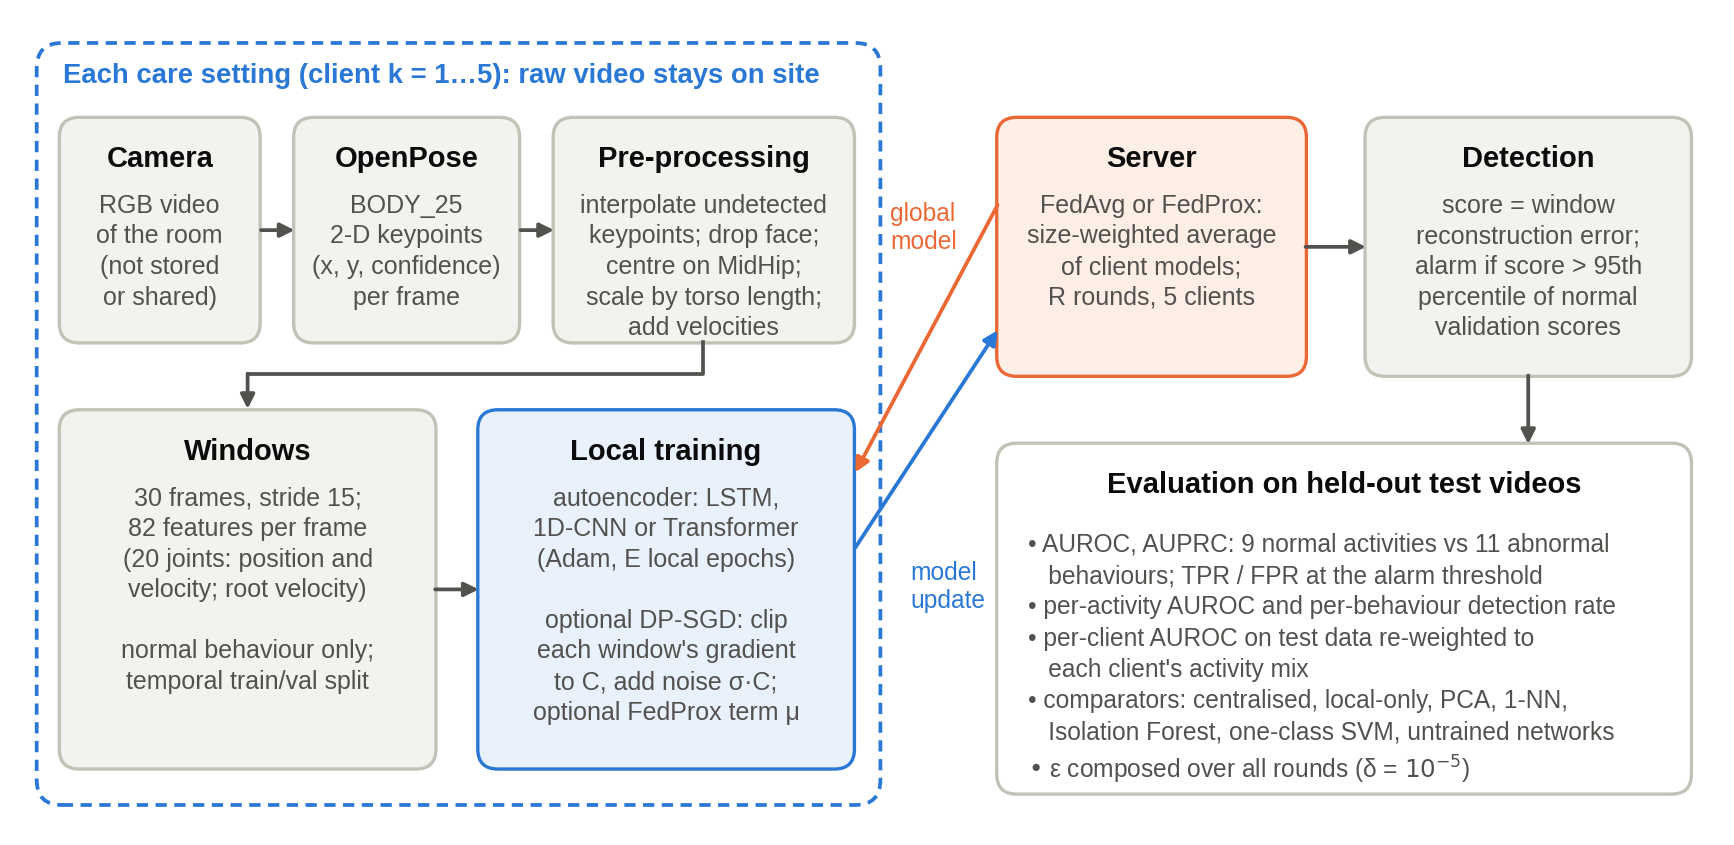

**Figure 2**

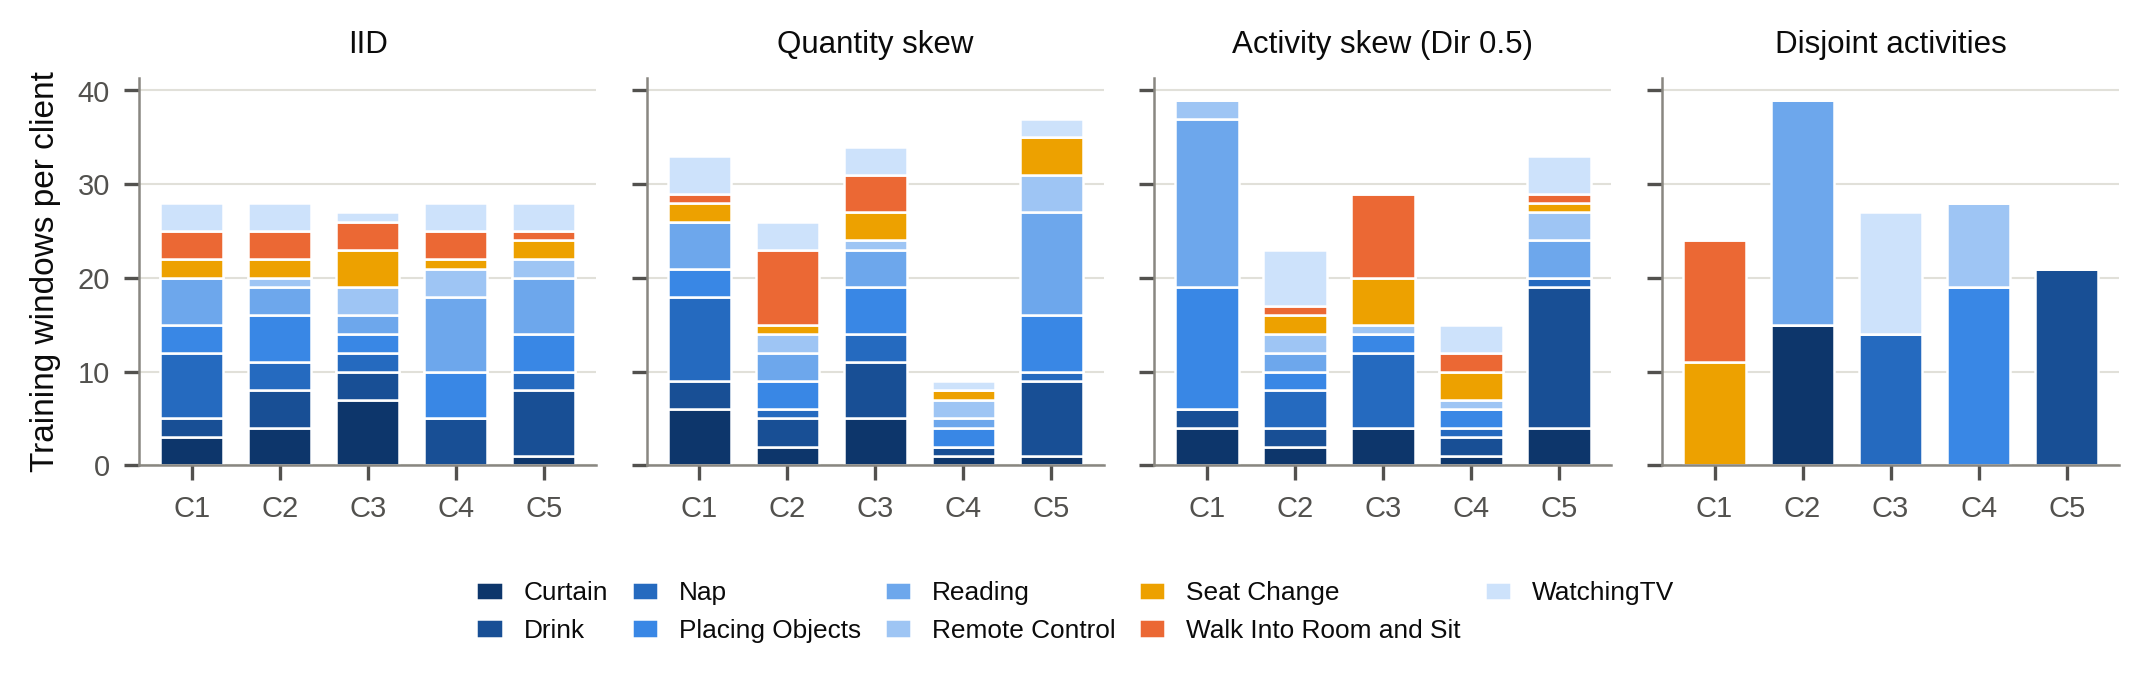

**Figure 3**

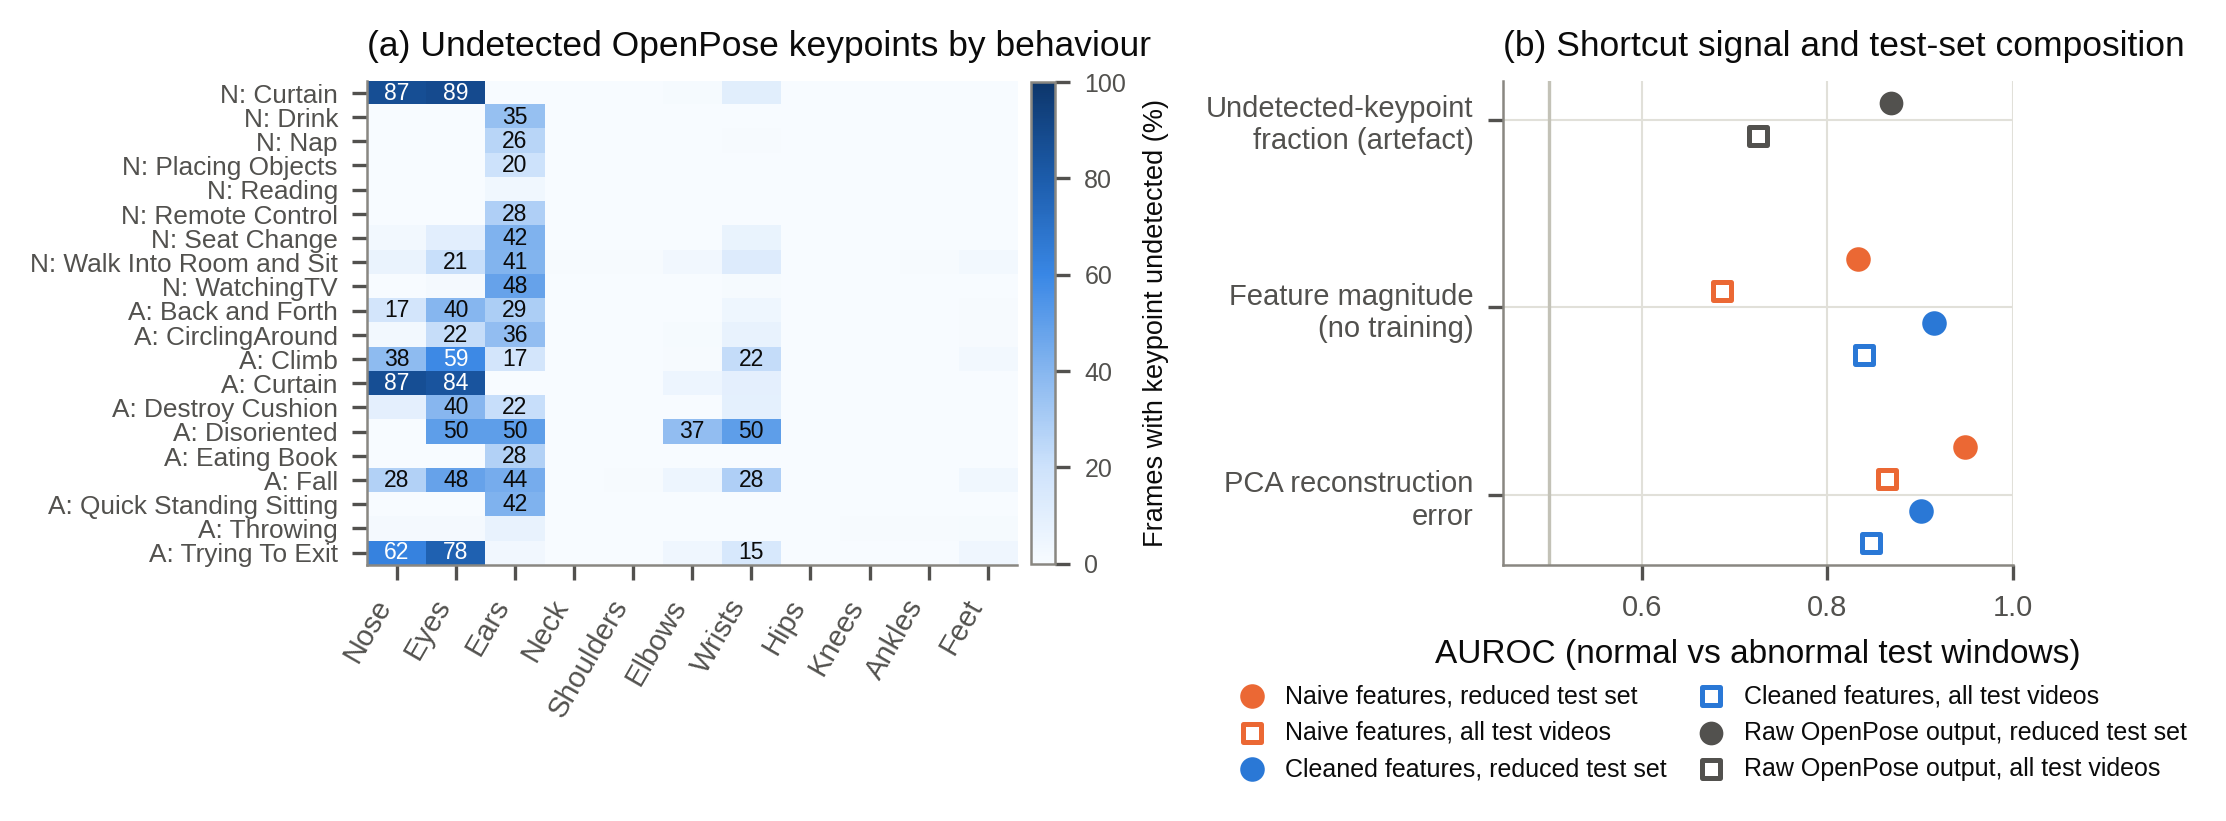

**Figure 4**

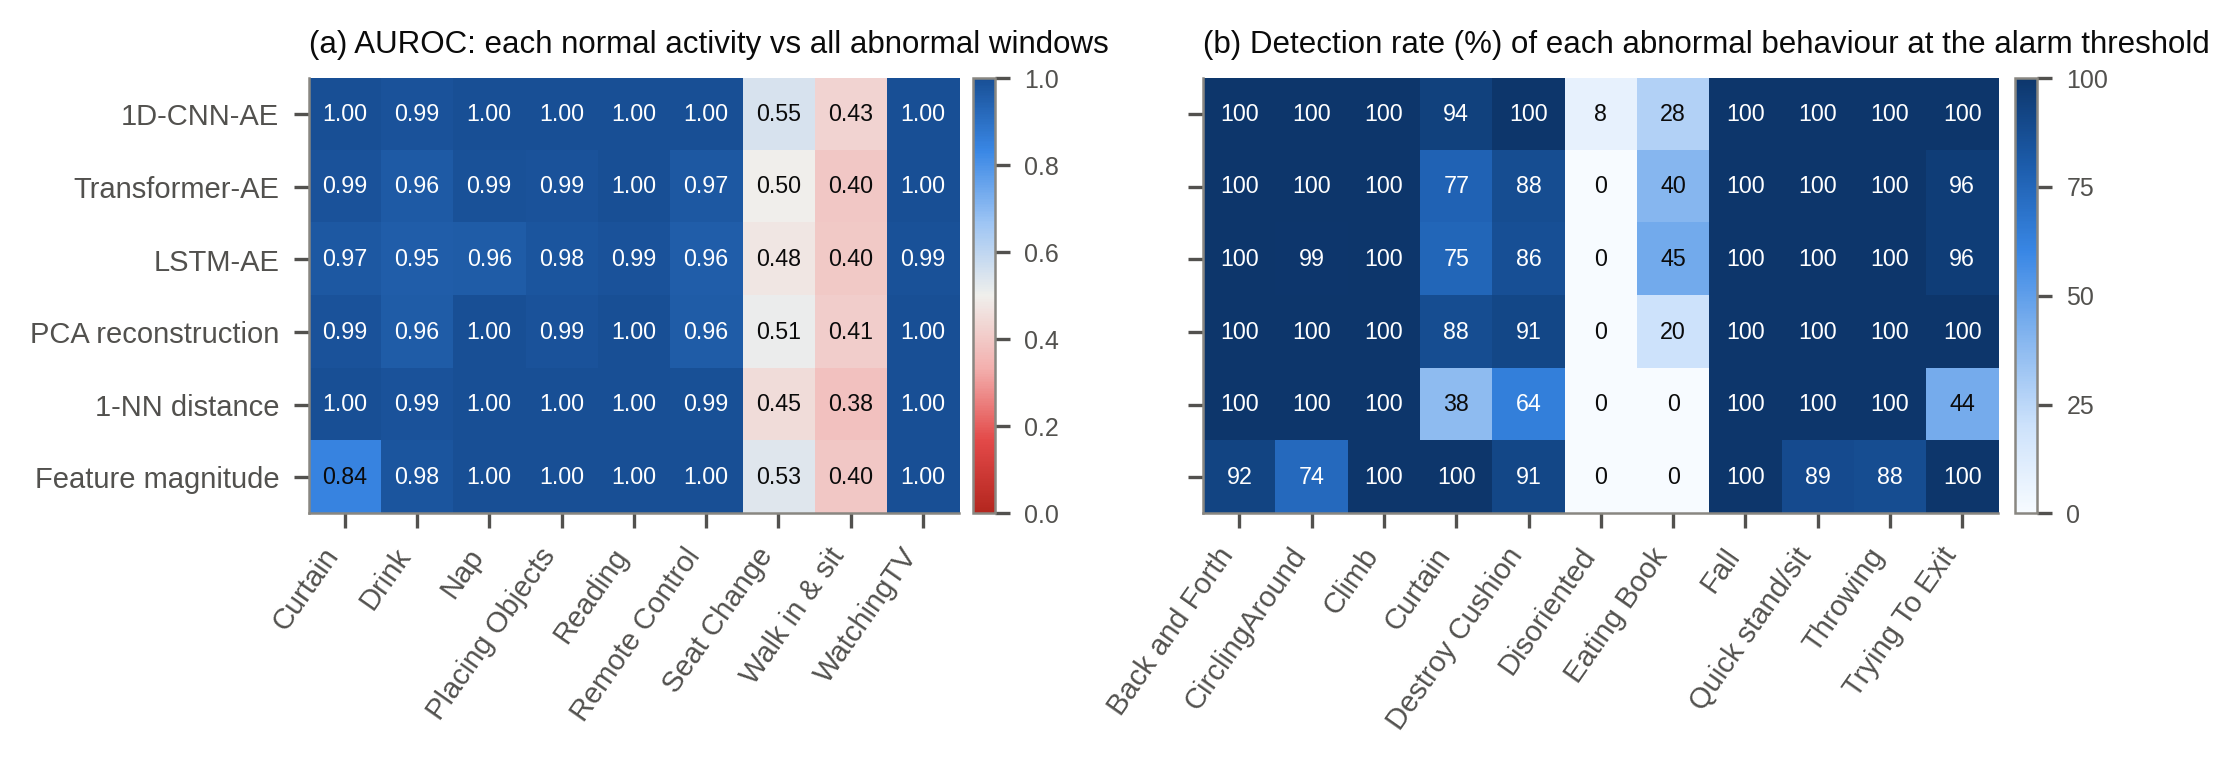

**Figure 5**

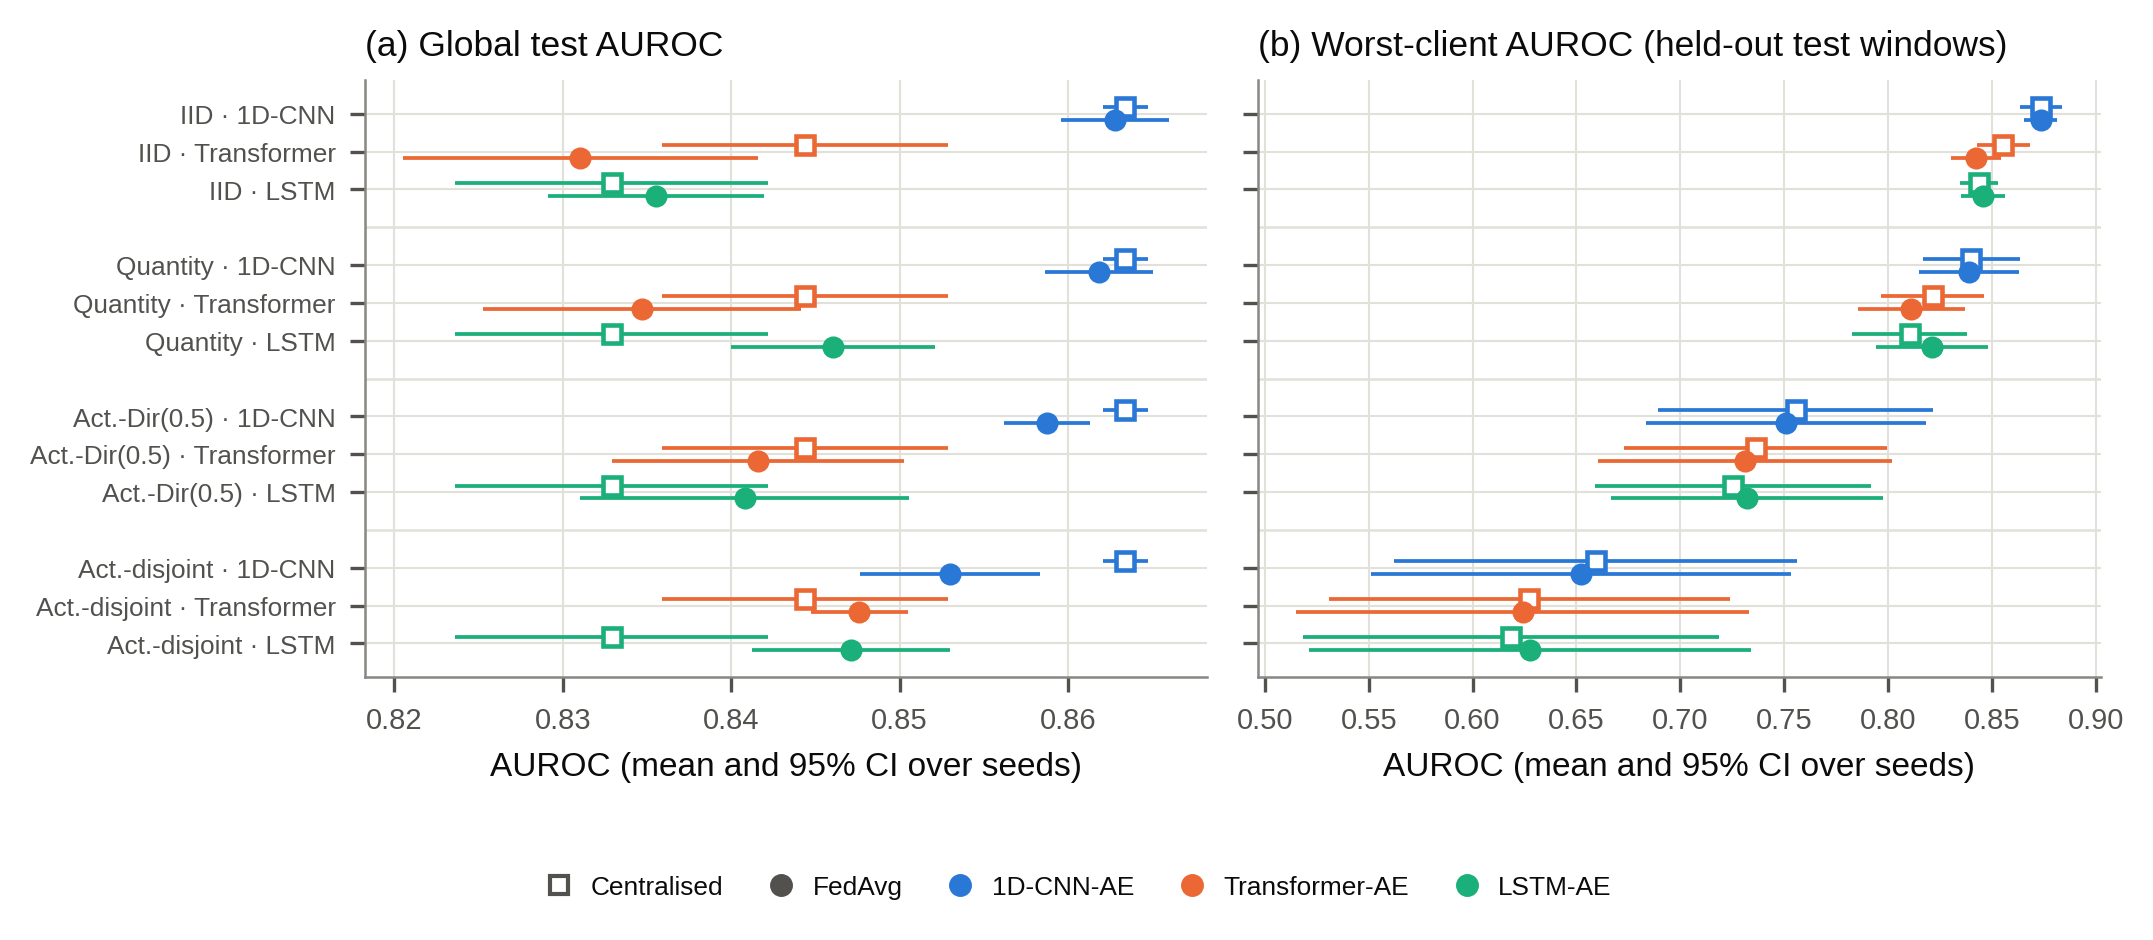

**Figure 6**

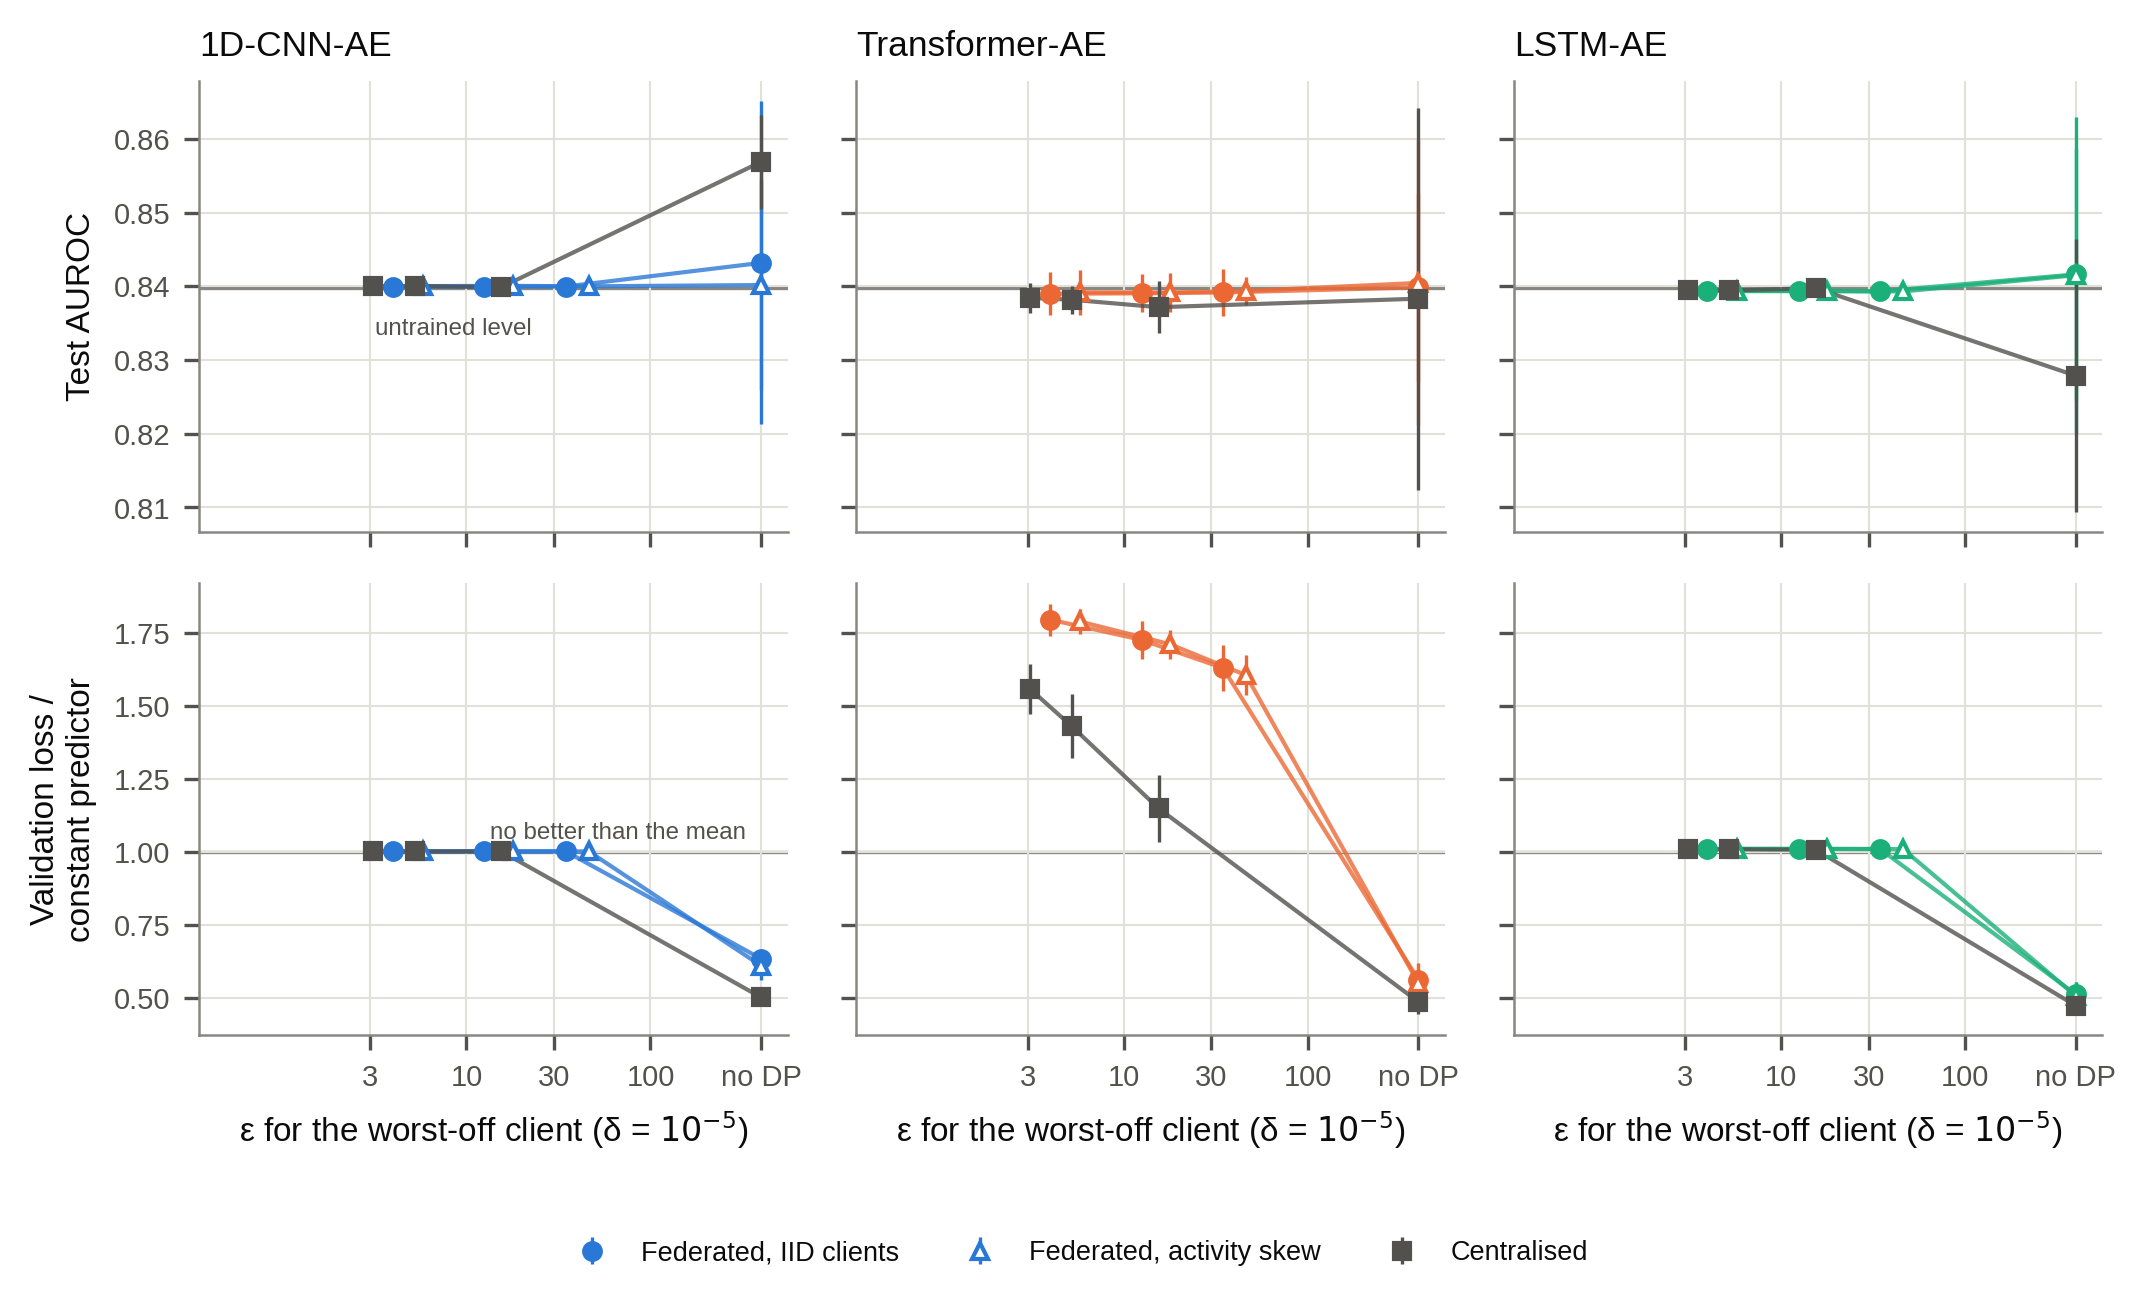

In [23]:
from IPython.display import Image, Markdown, display

tables = ['t_data', 't_shortcut', 't_central', 't_fed', 't_prox', 't_local', 't_dp', 't_eff', 't_lr']
for i, t in enumerate(tables):
    path = f'outputs/tables/{t}_ms.md'
    if os.path.exists(path):
        title = f'Table {i + 1}' if t != 't_lr' else 'Table A1'
        text = open(path).read().replace('^\u2212', '<sup>\u2212').replace('^ |', '</sup> |')
        display(Markdown(f'**{title}**\n\n' + text))

# file names of Figures 2 and 3 are swapped relative to the paper
figures = ['fig1_overview', 'fig3_partitions', 'fig2_shortcut', 'fig4_subgroups', 'fig5_federated', 'fig6_privacy']
for i, f in enumerate(figures):
    display(Markdown(f'**Figure {i + 1}**'))
    display(Image(f'outputs/figures/{f}.png', width=900))

In [24]:
# main results next to the values in the paper
paper = {
    'Centralised 1D-CNN-AE': ('cen_auroc::1D-CNN-AE', 0.863),
    'Centralised Transformer-AE': ('cen_auroc::Transformer-AE', 0.842),
    'Centralised LSTM-AE': ('cen_auroc::LSTM-AE', 0.833),
    'PCA': ('cen_auroc::PCA reconstruction (k=60)', 0.847),
    'FedAvg 1D-CNN-AE, IID': ('fed_auroc::iid::1D-CNN-AE', 0.863),
    'FedAvg 1D-CNN-AE, disjoint activities': ('fed_auroc::act_disjoint::1D-CNN-AE', 0.853),
    'Worst client, FedAvg 1D-CNN-AE, disjoint activities': ('fed_wc::act_disjoint::1D-CNN-AE', 0.652),
    'Largest FedAvg vs centralised gap': ('fed_d_auc_absmax', 0.014),
    'Epsilon, FedAvg IID, sigma = 1': ('dp_eps::FL, IID (R=20, E=2)::1.0', 34.586),
}
numbers = json.load(open('outputs/numbers.json'))
for label, (key, value) in paper.items():
    print(f'{label:55s} {numbers[key]:8.3f}   (paper {value})')

Centralised 1D-CNN-AE                                      0.863   (paper 0.863)
Centralised Transformer-AE                                 0.844   (paper 0.842)
Centralised LSTM-AE                                        0.833   (paper 0.833)
PCA                                                        0.847   (paper 0.847)
FedAvg 1D-CNN-AE, IID                                      0.863   (paper 0.863)
FedAvg 1D-CNN-AE, disjoint activities                      0.853   (paper 0.853)
Worst client, FedAvg 1D-CNN-AE, disjoint activities        0.652   (paper 0.652)
Largest FedAvg vs centralised gap                          0.014   (paper 0.014)
Epsilon, FedAvg IID, sigma = 1                            34.586   (paper 34.586)


In [25]:
# download everything as one zip (it is also kept in SAVE_DIR)
!cd "{SAVE_DIR}" && zip -qr /content/fedskel_results.zip results outputs
from google.colab import files
files.download('/content/fedskel_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>